# CS781 Phase 7 — Prior Case Retrieval — Arch 3: Encoder/decoder hybrid (Prefix-LM) (`ARCH = "prefixlm"`)
Adapts **your Phase-1 checkpoint** `P1_REPOS[ARCH]` (`best/`; bart = the v2 retrain) to prior case retrieval: for every
query case, rank the candidate pool of the same split and submit the top 7 candidate IDs; scored by Micro-F1@7
(Micro-Precision@7 / Micro-Recall@7 secondary).

| | |
|---|---|
| Backbone | Phase-1 prefix-LM `LlamaModel`, whole chunk as the bidirectional prefix by default (`ATTN`) |
| Long documents | the document's tokens are cut into chunks of `CHUNK_LEN` tokens starting every `CHUNK_STRIDE` tokens; a document with more than `MAX_CHUNKS` (training) / `MAX_CHUNKS_PRED` (encoding for ranking) chunks is represented by the chunks `CHUNK_SELECT` picks (`first`, `last`, `first_last`, `even`, `random` — `even` when encoding for ranking) |
| Representation (`REPR`) | chunk vector = token states pooled by `POOL`; `doc`: one vector per document, chunk vectors pooled by `DOC_POOL` (`mean` / `max` / `attn` / `gru`); `chunks`: one vector per chunk (multi-vector). Optional projection `PROJ` (`none` / `linear` / `mlp`). Queries and candidates share the encoder (bi-encoder) |
| Similarity (`SIM`) | `cos` or `dot`; `REPR = "chunks"`: score = mean over the query's chunks of the best-matching candidate chunk (max-sim). Logits = similarity / `TAU` |
| Training objective (`LOSS`) | `infonce` (one relevant candidate per training pair, softmax over every candidate in the batch, other relevant candidates of the query masked), `listwise` (ListNet: softmax over the batch's candidates vs a uniform target over the query's relevant ones), `pairwise` (RankNet logistic loss over every relevant / non-relevant candidate pair in the batch) |
| Negatives (`NEG_SOURCE`) | in-batch negatives always (other pairs' candidates that are not relevant to the query); plus `HARD_NEGS` per pair: `random` (uniform from the pool), `bm25` (from the top `NEG_DEPTH` non-relevant BM25 candidates), `teacher` (kd only: from the teacher's top `NEG_DEPTH`), `none` |
| Ranking | model scores over the whole pool (`EXCLUDE_SELF`: a query's own ID is never returned); optional `RERANK_TOPN` (model reorders BM25's top N) and `FUSION_WEIGHT` (mix of standardised model and BM25 scores) — both off by default; dev always reports the model alone and BM25 alone too |
| Methods (`METHOD`) | `full`, `partial` (top blocks only), `qlora` (4-bit NF4 frozen base + LoRA), `lorma` (LoRMA), `prompt` (prompt tuning), `ia3` (IA³), `kd` (a smaller student learns the teacher's query–candidate score distributions) |
| Outputs | `submission_<RUN_NAME>.zip` + run files (scores, efficiency numbers, per-query dev details, dev score matrix, the run's scores over the training pool for distillation) in private repo `<hf-user>/cs781-p7` under `runs/<RUN_NAME>/` |

**Before you start**
1. Runtime -> Change runtime type -> **T4 GPU**.
2. Secrets (key icon) -> `HF` = the **same** HF token as Phases 1–6 (reads your `cs781-p1-*` repos and the gated course
   dataset, writes `cs781-p7`).
3. Choose `METHOD`, `REPR`, `DOC_POOL`, `LOSS`, `NEG_SOURCE` in the first code cell, check *Configuration*, then **Run all**.

Another experiment on the same account: change the first cell (the run name follows), **Run all** again — every run
starts from the Phase-1 checkpoint; tokenised documents are cached in the runtime. `kd` needs a finished teacher run in
`cs781-p7` (`TEACHER_RUN`, any architecture: it saved `train_scores.npz`, its logits for every training query × every
training candidate).

Phase-7 rules (capstone §1, §13.2): ≥4 substantially different experiments, of which ≥3 use different fine-tuning /
adaptation techniques **from the §13.2.1 list** (full, partial / layer-wise, QLoRA, LoRMA, prefix tuning, prompt
tuning, IA³, KD) with **LoRMA compulsory**, and ≥1 is knowledge distillation from a larger or stronger teacher into a
smaller student; hyperparameter-only variations, and pooling / similarity / objective choices alone, do not count as
separate techniques. Every experiment starts from the Phase-1 model. Prefix tuning is not implemented here. BM25 is a
lexical scoring function (no pretrained weights); it is used for hard negatives and as a reference row, and only enters
the submitted ranking if you set `RERANK_TOPN` / `FUSION_WEIGHT` — whether that is acceptable for a submission is your call.

In [1]:
ARCH = "prefixlm"                 # fixed for this notebook
METHOD = "lorma"                  # "full" | "partial" | "qlora" | "lorma" | "prompt" | "ia3" | "kd"
REPR = "doc"                      # "doc" (one vector per document) | "chunks" (one vector per chunk, max-sim scoring)
DOC_POOL = "mean"                 # REPR "doc": "mean" | "max" | "attn" | "gru"
LOSS = "infonce"                  # "infonce" | "listwise" | "pairwise"
NEG_SOURCE = "random"             # "random" | "bm25" | "teacher" (kd only) | "none" (in-batch negatives only)
RUN_NAME = f"{ARCH}_{METHOD}_{DOC_POOL if REPR == 'doc' else 'maxsim'}_{LOSS}_{NEG_SOURCE}"   # unique per experiment

In [2]:
import os, json, math, time, random, zipfile, gc, hashlib
from collections import Counter
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from huggingface_hub import login, whoami, HfApi, hf_hub_download, snapshot_download

def get_hf_token():
    try:
        from google.colab import userdata
        return userdata.get("HF")
    except Exception:
        pass
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("HF")
    except Exception:
        return os.environ["HF_TOKEN"]

HF_TOKEN = get_hf_token()
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)
HF_USER = whoami(token=HF_TOKEN)["name"]
api = HfApi(token=HF_TOKEN)

def hub_push(fn, what, tries=3):
    for t in range(1, tries + 1):
        try:
            fn(); return True
        except Exception as e:
            print(f"  !! {what} upload failed ({t}/{tries}): {e!r}")
            time.sleep(30 * t)
    return False

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
assert DEVICE == "cuda" or os.environ.get("CS781_ALLOW_CPU"), "Switch the runtime to a GPU"
AMP = DEVICE == "cuda"
print(torch.__version__, torch.cuda.get_device_name(0) if AMP else "CPU")
import transformers; print("transformers", transformers.__version__)

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


2.14.1+cu130 Tesla T4
transformers 5.22.1


## Configuration — **all values below are YOUR CHOICE** (document them in the report)
The numbers filled in are placeholders that make the notebook run end to end on a T4, not tuned values.

In [3]:
DATASET = "Exploration-Lab/CS-781-Capstone"
DATA_DIR = "Phase_7_PCR"                    # folder of this phase in the dataset repo (searched for if the name differs)
# Phase-1 checkpoint (best/) per architecture; bart = the v2 retrain (v1 `cs781-p1-bart` collapsed, never use it)
P1_REPOS = {"llama": f"{HF_USER}/cs781-p1-llama", "bart": f"{HF_USER}/cs781-p1-bart-v2",
            "prefixlm": f"{HF_USER}/cs781-p1-prefixlm", "mistral_swa": f"{HF_USER}/cs781-p1-mistral_swa"}
P7_REPO = f"{HF_USER}/cs781-p7"             # all Phase-7 runs: runs/<RUN_NAME>/...
WORK = "/content/p7" if os.path.isdir("/content") else "/tmp/p7"
RUN_DIR = f"{WORK}/{RUN_NAME}"
CACHE_DIR = f"{WORK}/cache"                 # tokenised documents, reused by later runs in the same runtime
os.makedirs(RUN_DIR, exist_ok=True); os.makedirs(CACHE_DIR, exist_ok=True)

SEED = 42

# Long documents -> chunks -> vectors
CHUNK_LEN = 512            # tokens per chunk (Phase-1 positions: 1024; the bart encoder was pretrained on <= 768 tokens)
CHUNK_STRIDE = 512         # tokens between consecutive chunk starts (< CHUNK_LEN: overlapping chunks)
CHUNK_SELECT = "even"      # "first" | "last" | "first_last" | "even" | "random" (random in training only; even when encoding)
MAX_CHUNKS = 4             # chunks per document in training
MAX_CHUNKS_PRED = 8        # chunks per document when encoding queries / candidates for ranking
POOL = "mean"              # token states -> chunk vector: "mean" | "first" | "last"
ATT_HIDDEN = 256           # DOC_POOL "attn": hidden size of the attention scorer
GRU_HIDDEN = 256           # DOC_POOL "gru": hidden size per direction
PROJ = "none"              # "none" | "linear" | "mlp" (Linear -> GELU -> Linear): vector -> PROJ_DIM before scoring
PROJ_DIM = 256

# How the backbone attends inside a chunk
#   decoder-only models: "causal" (as pretrained) or "bidirectional" (full mask; for mistral_swa a ±window band)
ATTN = {"llama": "causal", "prefixlm": "bidirectional", "mistral_swa": "causal", "bart": "n/a"}[ARCH]
#   bart: "encoder" = encoder states only; "decoder" = chunk fed to encoder AND decoder, decoder states
BART_MODE = "encoder"

# Similarity and ranking
SIM = "cos"                # "cos" | "dot"
TAU = 0.05                 # logits = similarity / TAU (training losses, distillation, saved teacher scores)
EXCLUDE_SELF = True        # a query's own ID is never ranked (when it is in its own candidate pool)
RERANK_TOPN = None         # None = the model ranks the whole pool; N = the model reorders BM25's top N, the rest follow in BM25 order
FUSION_WEIGHT = 0.0        # submitted score = (1 - w) * z(model) + w * z(BM25), z = standardised per query; 0 = model only
BM25_K1, BM25_B = 1.2, 0.75
BM25_STOPWORDS = True      # drop scikit-learn's English stop-word list from the BM25 vocabulary (words: lowercase, >= 2 chars)
ZERO_SHOT_EVAL = True      # dev score of the untrained model (Phase-1 backbone, adapters at identity) before training

# Training batches: a micro-batch holds PAIRS_PER_BATCH (training query, relevant candidate) pairs + HARD_NEGS negatives
# per pair; every candidate in the micro-batch is scored against every query in it (in-batch negatives)
PAIRS_PER_BATCH = 4
HARD_NEGS = 1
NEG_DEPTH = 100            # NEG_SOURCE "bm25" / "teacher": negatives drawn uniformly from the top this many non-relevant candidates

# Optimisation
EPOCHS = 5                 # passes over the training pairs (MAX_TRAIN_MINUTES may end training first)
MAX_TRAIN_MINUTES = 60     # cap on training time, dev evaluations excluded; the LR schedule follows
                           # max(fraction of steps, fraction of this time), so it completes by the cap
EVAL_EVERY_MINUTES = 10    # dev evaluation after this many training minutes (and at the end of every epoch)
PATIENCE = 3               # dev evaluations without a Micro-F1@7 improvement before stopping
GRAD_ACCUM = 1             # micro-batches per optimizer step (in-batch negatives come from one micro-batch only)
PRED_BATCH_DOCS = 8        # documents per forward pass when encoding
GRAD_CKPT = True           # activation checkpointing in the backbone (less GPU memory, slower)
LR = {"full": 2e-5, "partial": 5e-5, "qlora": 5e-4, "lorma": 5e-4, "prompt": 3e-3, "ia3": 3e-3, "kd": 5e-5}[METHOD]
HEAD_LR = 1e-3             # document pooling (attn / gru) and projection
WEIGHT_DECAY = 0.01
WARMUP_FRAC = 0.06
GRAD_CLIP = 1.0

# Method-specific
PARTIAL_TOP = 4                         # partial: top blocks (+ final norm) trained, the rest of the backbone frozen
ADAPT_TARGETS = ["q_proj", "v_proj"]    # qlora / lorma: names of the nn.Linear layers that get adapters
RANK, ALPHA = 8, 16                     # qlora (LoRA) / lorma: rank, scale alpha/r
QLORA_BLOCK = 64                        # qlora: weights per NF4 quantisation block (one absmax per block)
QLORA_DOUBLE_QUANT = True               # qlora: absmax constants stored in 8 bits too (double quantisation)
LORMA_VARIANT = "plus"                  # "plus" = additive-identity rank inflation, "pi" = permutation inflation
IA3_OUT = ["k_proj", "v_proj"]          # ia3: outputs rescaled by a learned vector (keys, values)
IA3_IN = ["down_proj", "fc2"]           # ia3: inputs rescaled (FFN activation; llama/mistral down_proj, bart fc2)
PROMPT_LEN = 20                         # prompt: learned soft tokens prepended to every chunk

# Knowledge distillation (METHOD == "kd"); the student is this notebook's ARCH with fewer Phase-1 blocks
TEACHER_RUN = "llama_full_mean_infonce_random"   # a finished run in P7_REPO (it saved train_scores.npz)
STUDENT_LAYERS = None                   # None = every 2nd block (per stack for bart), or an explicit list
KD_T = 1.0
KD_ALPHA = 0.5                          # loss = KD_ALPHA * LOSS + (1 - KD_ALPHA) * T^2 * KL(teacher || student) over the
                                        # batch's candidates, both as softmax(logits / KD_T)

SAVE_TRAIN_SCORES = True   # logits for every training query x every training candidate (one encoding pass over the training
                           # pool), so a later kd run can use this run as teacher
SAVE_WEIGHTS = False       # fine-tuned weights to the Hub (not needed for distillation)

METHODS = ("full", "partial", "qlora", "lorma", "prompt", "ia3", "kd")
K_EVAL = 7                                     # the official cut-off
assert METHOD in METHODS, METHOD
assert REPR in ("doc", "chunks") and DOC_POOL in ("mean", "max", "attn", "gru")
assert LOSS in ("infonce", "listwise", "pairwise") and NEG_SOURCE in ("random", "bm25", "teacher", "none")
assert NEG_SOURCE != "teacher" or METHOD == "kd", "NEG_SOURCE 'teacher' needs METHOD 'kd'"
assert CHUNK_SELECT in ("first", "last", "first_last", "even", "random") and POOL in ("mean", "first", "last")
assert PROJ in ("none", "linear", "mlp") and SIM in ("cos", "dot") and TAU > 0
assert 0 < CHUNK_STRIDE <= CHUNK_LEN and MAX_CHUNKS >= 1 and MAX_CHUNKS_PRED >= 1
assert 0 <= FUSION_WEIGHT <= 1 and (RERANK_TOPN is None or RERANK_TOPN >= K_EVAL)
assert PAIRS_PER_BATCH >= 1 and HARD_NEGS >= 0 and NEG_DEPTH >= 1 and QLORA_BLOCK % 2 == 0
assert METHOD != "prompt" or ARCH != "bart" or BART_MODE == "encoder", "prompt tuning: BART_MODE = 'encoder' only"

def finished_runs():
    """Runs in P7_REPO that completed with distillation scores (a run uploads runs/<RUN_NAME>/ at the end)."""
    try:
        files = api.list_repo_files(P7_REPO)
    except Exception:                                # repo does not exist yet
        return []
    return sorted({f.split("/")[1] for f in files if f.startswith("runs/") and f.endswith("/train_scores.npz")})

if METHOD == "kd" and TEACHER_RUN not in (_done := finished_runs()):
    raise RuntimeError(f"TEACHER_RUN = {TEACHER_RUN!r} is not a finished run in {P7_REPO}. Set TEACHER_RUN to one of "
                       f"these finished runs: {_done or 'none yet -- let a non-kd run with SAVE_TRAIN_SCORES finish first'}")
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

## Data: download, inspect, parse
The raw first record of each file is printed so the format can be checked by eye. Query files: `{query ID: {text,
relevant_candidates}}` (a list of records with an `id` field is accepted too); `text` is a list of sentences, joined
with newlines. Candidate files: `{candidate ID: text or {text}}` (or a list of records). IDs are kept as the exact
strings in the files (leading zeros matter). As in `evaluate_phase7.py`, blank relevant IDs are ignored; a relevant ID
repeated in one list is kept once and counted. Measurements only — nothing else is removed.

In [4]:
_DS_FILES = None
def fetch(rel):
    global _DS_FILES
    try:
        return hf_hub_download(DATASET, f"{DATA_DIR}/{rel}", repo_type="dataset", token=HF_TOKEN)
    except Exception as e:
        if _DS_FILES is None:
            _DS_FILES = api.list_repo_files(DATASET, repo_type="dataset")
        hits = [f for f in _DS_FILES if f.lower().endswith(rel.lower().split("/")[-1])
                and any(t in f.lower() for t in ("phase_7", "phase7", "phase 7", "pcr"))]
        if len(hits) != 1:
            raise RuntimeError(f"{DATA_DIR}/{rel} not found ({e!r}); matching files: {hits}; "
                               f"json files in the dataset: {[f for f in _DS_FILES if f.endswith('.json')]}")
        print(f"  {DATA_DIR}/{rel} not found -> using {hits[0]}")
        return hf_hub_download(DATASET, hits[0], repo_type="dataset", token=HF_TOKEN)

def read_json_any(path):
    txt = open(path, encoding="utf-8").read()
    try:
        return json.loads(txt)
    except json.JSONDecodeError:                       # JSON Lines
        return [json.loads(l) for l in txt.splitlines() if l.strip()]

NON_STR_IDS = Counter()
def as_id(x, name):
    if not isinstance(x, str):
        NON_STR_IDS[name] += 1
    return str(x).strip()

def as_text(t):
    if isinstance(t, list):
        return "\n".join(map(str, t))
    return t

def items_of(raw, id_fields):
    if isinstance(raw, dict):
        return list(raw.items())
    return [(next((r[f] for f in id_fields if f in r), None), r) for r in raw]

def as_queries(raw, name):
    """-> [(id, text, relevant IDs or None, repeats dropped)]"""
    out = []
    for k, v in items_of(raw, ("id", "query_id", "qid")):
        if isinstance(v, (str, list)):
            text, rel = as_text(v), None
        else:
            text = as_text(next((v[f] for f in ("text", "query_text", "document") if f in v), None))
            rel = next((v[f] for f in ("relevant_candidates", "relevant", "labels", "gold") if f in v), None)
        assert k is not None and isinstance(text, str), f"{name}: unexpected record {repr(v)[:200]}"
        rep = 0
        if rel is not None:
            ids = [as_id(c, name) for c in (rel if isinstance(rel, list) else [rel])]
            ids = [c for c in ids if c]                               # blank IDs ignored (as the official script)
            rel = list(dict.fromkeys(ids)); rep = len(ids) - len(rel)
        out.append((as_id(k, name), text, rel, rep))
    return out

def as_candidates(raw, name):
    """-> [(id, text)]"""
    out = []
    for k, v in items_of(raw, ("id", "candidate_id", "cid")):
        text = as_text(v if isinstance(v, (str, list)) else next((v[f] for f in ("text", "document") if f in v), None))
        assert k is not None and isinstance(text, str), f"{name}: unexpected record {repr(v)[:200]}"
        out.append((as_id(k, name), text))
    return out

FILES = {"train": ("Train/train.json", "Train/train_candidates.json"), "dev": ("Dev/dev.json", "Dev/dev_candidates.json"),
         "test": ("Test/test.json", "Test/test_candidates.json")}
SPLITS = list(FILES)
QIDS, CIDS, GOLD, TEXT = {}, {}, {}, {}      # QIDS / CIDS[split]: ids in file order; GOLD[split][qid]; TEXT[(split, "q"|"c", id)]
for split, (qrel, crel) in FILES.items():
    for rel, role in ((qrel, "q"), (crel, "c")):
        t0 = time.time(); raw = read_json_any(fetch(rel))
        first = raw[next(iter(raw))] if isinstance(raw, dict) else raw[0]
        print(f"{rel}: {type(raw).__name__} of {len(raw)} ({time.time()-t0:.0f}s)  first record: {repr(first)[:300]}")
        recs = as_queries(raw, rel) if role == "q" else [(k, t, None, 0) for k, t in as_candidates(raw, rel)]
        del raw
        ids, dup, reps = [], 0, 0
        for k, text, rel_ids, rep in recs:
            key = (split, role, k)
            if key in TEXT:
                dup += 1; continue
            TEXT[key] = text; ids.append(k); reps += rep
            if role == "q":
                GOLD.setdefault(split, {})[k] = rel_ids
        if role == "q":
            QIDS[split] = ids
            if split != "test":
                assert all(GOLD[split][k] is not None for k in ids), f"{rel}: queries without relevant_candidates"
        else:
            CIDS[split] = ids
        del recs; gc.collect()
        if dup:
            print(f"  !! {dup} repeated IDs dropped (first kept)")
        if reps:
            print(f"  !! {reps} repeated relevant IDs inside lists dropped")
if NON_STR_IDS:
    print(f"!! IDs that are not JSON strings (converted with str(); leading zeros may be lost): {dict(NON_STR_IDS)}")

CIDX = {s: {c: i for i, c in enumerate(CIDS[s])} for s in SPLITS}
SELF = {}                                    # split -> (query rows, pool columns) of queries that are in their own pool
print(f"\n{'split':6s} {'queries':>7s} {'pool':>6s} {'relevant/query mean':>19s} {'min':>4s} {'max':>4s} {'none':>5s} "
      f"{'relevant not in pool':>20s} {'queries in own pool':>19s} {'self relevant':>13s}")
for s in SPLITS:
    rows = [(i, CIDX[s][q]) for i, q in enumerate(QIDS[s]) if q in CIDX[s]]
    SELF[s] = (np.array([r for r, _ in rows], dtype=np.int64), np.array([c for _, c in rows], dtype=np.int64))
    assert len(CIDS[s]) >= K_EVAL + 1, f"{s}: candidate pool smaller than {K_EVAL} + 1"
    if s == "test":
        print(f"{s:6s} {len(QIDS[s]):7d} {len(CIDS[s]):6d} {'-':>19s} {'-':>4s} {'-':>4s} {'-':>5s} {'-':>20s} {len(rows):19d} {'-':>13s}")
        continue
    n = np.array([len(GOLD[s][q]) for q in QIDS[s]])
    out = sum(c not in CIDX[s] for q in QIDS[s] for c in GOLD[s][q])
    selfrel = sum(q in GOLD[s][q] for q in QIDS[s])
    print(f"{s:6s} {len(QIDS[s]):7d} {len(CIDS[s]):6d} {n.mean():19.2f} {n.min():4d} {n.max():4d} {(n == 0).sum():5d} "
          f"{out:20d} {len(rows):19d} {selfrel:13d}")
print(f"\n{'documents':16s} {'chars median':>12s} {'p90':>9s} {'max':>9s} {'empty':>6s}")
for s in SPLITS:
    for role, ids in (("q", QIDS[s]), ("c", CIDS[s])):
        ch = np.array([len(TEXT[(s, role, k)]) for k in ids])
        print(f"{s + (' queries' if role == 'q' else ' candidates'):16s} {int(np.median(ch)):12d} "
              f"{int(np.percentile(ch, 90)):9d} {ch.max():9d} {(ch == 0).sum():6d}")
for a, b in (("train", "dev"), ("train", "test"), ("dev", "test")):
    print(f"shared IDs {a}/{b}: candidates {len(set(CIDS[a]) & set(CIDS[b]))}  queries {len(set(QIDS[a]) & set(QIDS[b]))}  "
          f"{a} queries in {b} pool {len(set(QIDS[a]) & set(CIDS[b]))}")
gold_pop = Counter(c for q in QIDS["train"] for c in GOLD["train"][q])
print(f"train: {len(gold_pop)} distinct relevant candidates; most often relevant (ID: queries): "
      + "  ".join(f"{c}: {n}" for c, n in gold_pop.most_common(8)))

# training pairs: (query, relevant candidate in the training pool), the query itself excluded
TRAIN_POS = {q: [CIDX["train"][c] for c in GOLD["train"][q] if c in CIDX["train"] and c != q] for q in QIDS["train"]}
TRAIN_Q = [q for q in QIDS["train"] if TRAIN_POS[q]]
print(f"training queries with >= 1 relevant candidate in the training pool: {len(TRAIN_Q)} of {len(QIDS['train'])};  "
      f"training pairs: {sum(len(TRAIN_POS[q]) for q in TRAIN_Q)}")

Phase_7_PCR/Train/train.json: reconstructing file:   0%|          |  0.00B / 33.2MB            

Phase_7_PCR/Train/train.json: downloading bytes:           |  0.00B            

Train/train.json: dict of 827 (2s)  first record: {'text': ['PETITIONER: <NAME> Vs. RESPONDENT: ROOP SINGH RATHORE & OTHERS(and connected appeal) DATE OF JUDGMENT: 07/05/1963 BENCH: <NAME>, S.K. BENCH: <NAME>, S.K. SINHA, BHUVNESHWAR P.(CJ) DAYAL, RAGHUBAR AYYANGAR, <NAME> MUDHOLKAR, J.R. CITATION: 1964 AIR 1545 1964 SCR (3) 573 CITATOR INFO : R 19


Phase_7_PCR/Train/train_candidates.json: reconstructing file:   0%|          |  0.00B /  160MB            

Phase_7_PCR/Train/train_candidates.json: downloading bytes:           |  0.00B            

Train/train_candidates.json: dict of 4320 (6s)  first record: {'text': ['JUDGMENT <NAME>, C.J. ', '1. The only point which has to be considered in this appeal is whether or not the lower appellate Court was wrong in admitting in evidence statements contained in two Exhibits, being Ex. 58 and 59 in the suit. ', '2. The case of the plaintiffs in the suit was tha


... (6 outputs left out)

Test/test.json: dict of 237 (1s)  first record: {'text': ["PETITIONER: <NAME> Vs. RESPONDENT: <NAME> & ORS. DATE OF JUDGMENT26/09/1989 BENCH: <NAME>, <NAME> (J) BENCH: <NAME>, <NAME> (J) RAY, <NAME> (J) CITATION: 1990 AIR 209 1989 SCR Supl. (1) 292 1990 SCC (1) 445 JT 1989 (4) 38 1989 SCALE (2)677 ACT: Criminal Trial--Criminal charge must be brou


Phase_7_PCR/Test/test_candidates.json: reconstructing file:   0%|          |  0.00B / 71.1MB            

Phase_7_PCR/Test/test_candidates.json: downloading bytes:           |  0.00B            

Test/test_candidates.json: dict of 1727 (6s)  first record: {'text': ['JUDGMENT <NAME>, J. ', '1. This appeal with special leave is directed against the order of <ORG>, Madras "A" Bench, dated August 8, 1952, made in I. T. A. No. 3254 of 1951-52 allowing the appeal and reversing the order of the Appellate Assistant Commissioner in I. T. A. No. 130 of 1949-50

split  queries   pool relevant/query mean  min  max  none relevant not in pool queries in own pool self relevant
train      827   4320                6.42    0   52    10                    0                 827             0
dev        118   1023                8.25    1   92     0                    0                 118             0
test       237   1727                   -    -    -     -                    -                 237             -

documents        chars median       p90       max  empty
train queries           25893     72937    717260      0
train candidates        20848     71744   2425986      0
dev queries   

## Ranking, official scoring, BM25 reference
`rank_metrics` computes Micro-P/R/F1@7 exactly as `evaluate_phase7.py` (TP = relevant IDs among the top 7, FP = the
other top-7 IDs, FN = relevant IDs not in the top 7 — including relevant IDs outside the pool, which no system can
return), plus threshold-free diagnostics: Recall@K over all relevant IDs, MRR of the first relevant candidate.
`final_scores` applies `FUSION_WEIGHT` / `RERANK_TOPN` / `EXCLUDE_SELF` to a (queries × pool) model score matrix.
BM25 (Okapi; IDF `log(1 + (N − df + 0.5) / (df + 0.5))`, vocabulary and statistics from the split's candidate pool,
query = its distinct words) is computed for every split: dev reference, hard negatives, optional fusion / reranking.

In [5]:
from sklearn.feature_extraction.text import CountVectorizer
import scipy.sparse as sp

GOLD_IDX = {s: [np.array([CIDX[s][c] for c in GOLD[s][q] if c in CIDX[s]], dtype=np.int64) for q in QIDS[s]]
            for s in ("train", "dev")}
N_GOLD = {s: [len(GOLD[s][q]) for q in QIDS[s]] for s in ("train", "dev")}

def bm25_scores(split):
    t0 = time.time()
    cv = CountVectorizer(lowercase=True, stop_words="english" if BM25_STOPWORDS else None, dtype=np.float32)
    X = cv.fit_transform([TEXT[(split, "c", c)] for c in CIDS[split]]).tocsr()
    dl = np.asarray(X.sum(1)).ravel(); avg = max(dl.mean(), 1e-9)
    df = np.bincount(X.indices, minlength=X.shape[1]); N = X.shape[0]
    idf = np.log(1 + (N - df + 0.5) / (df + 0.5)).astype(np.float32)
    rows = np.repeat(np.arange(N), np.diff(X.indptr)); tf = X.data
    w = idf[X.indices] * tf * (BM25_K1 + 1) / (tf + BM25_K1 * (1 - BM25_B + BM25_B * dl[rows] / avg))
    W = sp.csr_matrix((w.astype(np.float32), X.indices, X.indptr), shape=X.shape)
    Qb = (cv.transform([TEXT[(split, "q", q)] for q in QIDS[split]]) > 0).astype(np.float32)
    S = np.asarray((Qb @ W.T).todense(), dtype=np.float32)
    print(f"BM25 {split}: {len(QIDS[split])} queries x {N} candidates, vocabulary {X.shape[1]} words ({time.time()-t0:.0f}s)")
    return S

BM25 = {s: bm25_scores(s) for s in SPLITS}

def zrow(S):
    return (S - S.mean(1, keepdims=True)) / np.maximum(S.std(1, keepdims=True), 1e-9)

def final_scores(S, split, model_only=False):
    """(queries x pool) model scores -> scores whose descending order is the submitted ranking"""
    S = np.array(S, dtype=np.float64)
    if not model_only:
        B = BM25[split].astype(np.float64)
        if FUSION_WEIGHT:
            S = (1 - FUSION_WEIGHT) * zrow(S) + FUSION_WEIGHT * zrow(B)
        if RERANK_TOPN:
            top = np.argsort(-B, 1, kind="stable")[:, :RERANK_TOPN]
            inN = np.zeros(S.shape, dtype=bool); np.put_along_axis(inN, top, True, 1)
            S = np.where(inN, 1e9 + np.clip(S, -1e8, 1e8), np.clip(B, -1e8, 1e8))
    if EXCLUDE_SELF and len(SELF[split][0]):
        S[SELF[split]] = -np.inf
    return S

def ranking(S, k=None):
    o = np.argsort(-S, 1, kind="stable")
    return o if k is None else o[:, :k]

KS = (7, 20, 50, 100)
def rank_metrics(S, split):
    """official Micro-P/R/F1@7 (+ Recall@K, MRR) of a final score matrix of `split` (train / dev)"""
    order = ranking(S)
    rank = np.empty_like(order); np.put_along_axis(rank, order, np.arange(S.shape[1])[None].repeat(len(S), 0), 1)
    tp, hits, rr, zero = 0, Counter(), [], 0
    for i, g in enumerate(GOLD_IDX[split]):
        r = rank[i, g]
        h = int((r < K_EVAL).sum()); tp += h; zero += h == 0 and N_GOLD[split][i] > 0
        for k in KS: hits[k] += int((r < k).sum())
        rr.append(1.0 / (r.min() + 1) if len(r) else 0.0)
    ng, nq = sum(N_GOLD[split]), len(S)
    fp, fn = K_EVAL * nq - tp, ng - tp
    return {"F1": 2 * tp / max(2 * tp + fp + fn, 1), "P": tp / max(tp + fp, 1), "R": tp / max(tp + fn, 1),
            **{f"R@{k}": hits[k] / max(ng, 1) for k in KS}, "MRR": float(np.mean(rr)), "tp": tp, "fp": fp, "fn": fn,
            "zero_hit_queries": int(zero), "n": nq}

def official_scores(gold, pred):
    """exactly evaluate_phase7.py's score(): gold / pred dicts query ID -> list of candidate IDs"""
    tp = fp = fn = 0
    for q, labels in gold.items():
        g = set(labels); p = set(pred[q][:K_EVAL]); tp += len(g & p); fp += len(p - g); fn += len(g - p)
    return {"F1": (2 * tp) / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0, "P": tp / (tp + fp) if tp + fp else 0.0,
            "R": tp / (tp + fn) if tp + fn else 0.0, "tp": tp, "fp": fp, "fn": fn}

def validate(pred, split):
    """the official validation rules: every query, exactly 7 unique IDs from the split's pool"""
    assert isinstance(pred, dict) and set(pred) == set(QIDS[split])
    pool = CIDX[split]
    for q, v in pred.items():
        assert isinstance(v, list) and len(v) == K_EVAL and len(set(v)) == K_EVAL, q
        assert all(isinstance(c, str) and c.strip() and c in pool for c in v), q

def to_pred(S, split):
    top = ranking(S, K_EVAL)
    return {q: [CIDS[split][j] for j in top[i]] for i, q in enumerate(QIDS[split])}

def fmt(r):
    return (f"F1@7 {r['F1']:.4f}  P@7 {r['P']:.4f}  R@7 {r['R']:.4f}  " + "  ".join(f"R@{k} {r[f'R@{k}']:.4f}" for k in KS[1:])
            + f"  MRR {r['MRR']:.4f}  (no hit in top 7: {r['zero_hit_queries']} of {r['n']} queries)")

REFERENCE = {}
S_b = final_scores(BM25["dev"], "dev", model_only=True)
REFERENCE["bm25"] = rank_metrics(S_b, "dev")
off = official_scores({q: GOLD["dev"][q] for q in QIDS["dev"]}, to_pred(S_b, "dev"))
assert all(abs(off[m] - REFERENCE["bm25"][m]) < 1e-12 for m in off), (off, REFERENCE["bm25"])
nq, ng = len(QIDS["dev"]), sum(N_GOLD["dev"])
pool_n = len(CIDS["dev"]) - (1 if EXCLUDE_SELF else 0)
exp_tp = sum(K_EVAL * len(g) / pool_n for g in GOLD_IDX["dev"])
best_tp = sum(min(K_EVAL, len(g)) for g in GOLD_IDX["dev"])
REFERENCE["random_expected"] = {"F1": 2 * exp_tp / (K_EVAL * nq + ng), "P": exp_tp / (K_EVAL * nq), "R": exp_tp / max(ng, 1)}
REFERENCE["oracle"] = {"F1": 2 * best_tp / (K_EVAL * nq + ng), "P": best_tp / (K_EVAL * nq), "R": best_tp / max(ng, 1)}
print(f"\ndev references -- BM25 alone: {fmt(REFERENCE['bm25'])}  (identical to the evaluate_phase7.py computation)")
for name in ("random_expected", "oracle"):
    r = REFERENCE[name]
    print(f"dev references -- {name} (top 7{' = as many relevant in-pool IDs as possible' if name == 'oracle' else ' drawn uniformly'}): "
          f"F1@7 {r['F1']:.4f}  P@7 {r['P']:.4f}  R@7 {r['R']:.4f}")
r_tr = rank_metrics(final_scores(BM25["train"], "train", model_only=True), "train")
print(f"train references -- BM25 alone: {fmt(r_tr)}")
REFERENCE["bm25_train"] = r_tr

BM25 train: 827 queries x 4320 candidates, vocabulary 98217 words (24s)
BM25 dev: 118 queries x 1023 candidates, vocabulary 50923 words (5s)
BM25 test: 237 queries x 1727 candidates, vocabulary 64335 words (9s)

dev references -- BM25 alone: F1@7 0.1123  P@7 0.1223  R@7 0.1038  R@20 0.1644  R@50 0.2415  R@100 0.3422  MRR 0.3618  (no hit in top 7: 57 of 118 queries)  (identical to the evaluate_phase7.py computation)
dev references -- random_expected (top 7 drawn uniformly): F1@7 0.0074  P@7 0.0081  R@7 0.0068
dev references -- oracle (top 7 = as many relevant in-pool IDs as possible): F1@7 0.6181  P@7 0.6731  R@7 0.5714
train references -- BM25 alone: F1@7 0.1117  P@7 0.1071  R@7 0.1168  R@20 0.1777  R@50 0.2415  R@100 0.3092  MRR 0.3303  (no hit in top 7: 426 of 827 queries)


## Knowledge-distillation targets (only when `METHOD == "kd"`)
The teacher run saved `train_scores.npz`: its logits (similarity / its `TAU`) for every training query × every training
candidate. The student matches `softmax(teacher logits / KD_T)` over the candidates of each micro-batch.

In [6]:
TEACHER, teacher_info = None, None
if METHOD == "kd":
    teacher_info = json.load(open(hf_hub_download(P7_REPO, f"runs/{TEACHER_RUN}/run_config.json", token=HF_TOKEN,
                                                  force_download=True)))
    z = np.load(hf_hub_download(P7_REPO, f"runs/{TEACHER_RUN}/train_scores.npz", token=HF_TOKEN, force_download=True))
    tq, tc, tl = z["query_ids"].tolist(), z["cand_ids"].tolist(), z["logits"].astype(np.float32)
    assert set(tc) == set(CIDS["train"]), "the teacher's training pool differs from this run's"
    pos = {c: i for i, c in enumerate(tc)}
    col = np.array([pos[c] for c in CIDS["train"]])
    TEACHER = {q: tl[i, col] for i, q in enumerate(tq)}                              # pool order of this run
    n_before = len(TRAIN_Q)
    TRAIN_Q = [q for q in TRAIN_Q if q in TEACHER]
    assert TRAIN_Q, "the teacher has scores for none of this run's training queries"
    tv = teacher_info["dev"]
    print(f"teacher {TEACHER_RUN}: {teacher_info['arch']}/{teacher_info['method']}, {teacher_info['params_final']/1e6:.1f}M "
          f"params, dev F1@7 {tv['F1']:.4f}, dev encoding {teacher_info['dev_encode_seconds']:.1f}s;  "
          f"{len(TRAIN_Q)} of {n_before} training queries have teacher scores")
    t_tr = rank_metrics(final_scores(np.stack([TEACHER.get(q, np.zeros(len(CIDS['train']), np.float32)) for q in QIDS['train']]),
                                     "train", model_only=True), "train")
    print(f"teacher scores on the training queries: {fmt(t_tr)}")
    del z, tl

## Tokenizer and document tokens
Each document is tokenised as a whole (no special tokens) and stored as `uint16` ids; an empty document becomes a single
`<|endoftext|>`. Tokenised documents are cached in `CACHE_DIR`, keyed by the tokenizer file.

In [7]:
from transformers import PreTrainedTokenizerFast

P1_DIRS = {}
def p1_dir(arch):
    if arch not in P1_DIRS:
        try:
            path = snapshot_download(P1_REPOS[arch], token=HF_TOKEN, allow_patterns=["best/*"])
        except Exception as e:
            raise RuntimeError(f"cannot read {P1_REPOS[arch]}/best -- has its Phase-1 notebook finished? ({e!r})")
        P1_DIRS[arch] = os.path.join(path, "best")
    return P1_DIRS[arch]

tokenizer = PreTrainedTokenizerFast.from_pretrained(p1_dir(ARCH))
tokenizer.model_max_length = 10**9
PAD_ID, EOS_ID, VOCAB = tokenizer.pad_token_id, tokenizer.eos_token_id, len(tokenizer)
assert VOCAB <= 65535, "token ids are stored as uint16"
TOK_FP = hashlib.md5(open(os.path.join(p1_dir(ARCH), "tokenizer.json"), "rb").read()).hexdigest()[:12]

def tokenize_part(split, role, ids, bs=128):
    path = f"{CACHE_DIR}/{split}_{role}_{TOK_FP}.npz"
    have = {}
    if os.path.exists(path):
        z = np.load(path)
        offs, flat = z["offsets"], z["flat"]
        have = {k: flat[offs[i]:offs[i + 1]] for i, k in enumerate(z["ids"].tolist())}
    need = [k for k in ids if k not in have]
    t0 = time.time()
    for i in range(0, len(need), bs):
        part = need[i:i + bs]
        enc = tokenizer([TEXT[(split, role, k)] for k in part], add_special_tokens=False)["input_ids"]
        for k, x in zip(part, enc):
            have[k] = np.asarray(x, dtype=np.uint16)
        if (i // bs) % 20 == 19:
            print(f"  {split}/{role}: {i + len(part)}/{len(need)} documents tokenised ({time.time()-t0:.0f}s)")
    if need:
        keys = list(have)
        lens = np.array([len(have[k]) for k in keys], dtype=np.int64)
        np.savez(path, ids=np.array(keys), offsets=np.concatenate([[0], np.cumsum(lens)]),
                 flat=np.concatenate([have[k] for k in keys]))
    print(f"{split} {'queries' if role == 'q' else 'candidates'}: {len(ids)} documents ({len(ids) - len(need)} from cache, "
          f"{len(need)} tokenised in {time.time()-t0:.0f}s)")
    return {(split, role, k): have[k] if len(have[k]) else np.array([EOS_ID], dtype=np.uint16) for k in ids}

TOK = {}
for s in SPLITS:
    TOK.update(tokenize_part(s, "q", QIDS[s])); TOK.update(tokenize_part(s, "c", CIDS[s]))
del TEXT; gc.collect()
QKEYS = {s: [(s, "q", q) for q in QIDS[s]] for s in SPLITS}
CKEYS = {s: [(s, "c", c) for c in CIDS[s]] for s in SPLITS}

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

train queries: 827 documents (0 from cache, 827 tokenised in 23s)
  train/c: 2560/4320 documents tokenised (50s)
train candidates: 4320 documents (0 from cache, 4320 tokenised in 87s)
dev queries: 118 documents (0 from cache, 118 tokenised in 4s)
dev candidates: 1023 documents (0 from cache, 1023 tokenised in 28s)
test queries: 237 documents (0 from cache, 237 tokenised in 4s)
test candidates: 1727 documents (0 from cache, 1727 tokenised in 38s)


## Chunks and batches
Chunk starts are `0, CHUNK_STRIDE, 2·CHUNK_STRIDE, …`, plus a last chunk ending exactly at the document's end, so every
token is in at least one chunk; `CHUNK_SELECT` then picks at most `MAX_CHUNKS` / `MAX_CHUNKS_PRED` of them, kept in
document order. A batch holds the selected chunks of several documents as rows of one `(Q, L)` tensor.

**Checks**: chunks cover every token of every document; pooling + regrouping returns each document's own chunks in order
(verified by pooling the token ids themselves).

In [8]:
TRAIN_RNG = np.random.default_rng(SEED)

def chunk_starts(n):
    if n <= CHUNK_LEN:
        return [0]
    s = list(range(0, n - CHUNK_LEN + 1, CHUNK_STRIDE))
    if s[-1] + CHUNK_LEN < n:
        s.append(n - CHUNK_LEN)
    return s

def select_chunks(key, k, train):
    starts = chunk_starts(len(TOK[key])); m = len(starts)
    if m <= k:
        return starts
    mode = CHUNK_SELECT if (train or CHUNK_SELECT != "random") else "even"
    if mode == "random":
        idx = np.sort(TRAIN_RNG.choice(m, size=k, replace=False))
    elif mode == "first":
        idx = range(k)
    elif mode == "last":
        idx = range(m - k, m)
    elif mode == "first_last":
        h = (k + 1) // 2; idx = list(range(h)) + list(range(m - (k - h), m))
    else:                                                          # even
        idx = np.linspace(0, m - 1, k).round().astype(int)
    return [starts[i] for i in idx]

def collate(jobs):
    """jobs: list of (key, chunk starts) -> dict of tensors: ids / att (Q, L) one row per chunk; doc / slot (Q,) the row's
    document in the batch and its place among that document's chunks; n = number of documents"""
    seqs, doc, slot = [], [], []
    for i, (key, starts) in enumerate(jobs):
        t = TOK[key]
        for j, s in enumerate(starts):
            seqs.append(t[s:s + CHUNK_LEN]); doc.append(i); slot.append(j)
    Q, L = len(seqs), max(map(len, seqs))
    ids = torch.full((Q, L), PAD_ID, dtype=torch.long); att = torch.zeros((Q, L), dtype=torch.long)
    for q, c in enumerate(seqs):
        ids[q, :len(c)] = torch.from_numpy(c.astype(np.int64)); att[q, :len(c)] = 1
    return dict(ids=ids, att=att, doc=torch.tensor(doc), slot=torch.tensor(slot), n=torch.tensor(len(jobs)))

def to_dev(batch):
    return {k: v.to(DEVICE) for k, v in batch.items()}

def pool_tokens(h, att):
    """(Q, L, H) token states + (Q, L) mask (real tokens first) -> (Q, H) float32 (float64 kept) chunk vectors, by POOL"""
    h = h if h.dtype == torch.float64 else h.float()
    if POOL == "mean":
        m = att[..., None].to(h.dtype)
        return (h * m).sum(1) / m.sum(1).clamp(min=1)
    if POOL == "first":
        return h[:, 0]
    return h[torch.arange(len(h), device=h.device), att.sum(1) - 1]

def group_chunks(cv, b):
    """(Q, H) chunk vectors -> (B, K, H) per document in document order + (B, K) mask of real chunks"""
    B, K = int(b["n"]), int(b["slot"].max()) + 1
    x = cv.new_zeros(B, K, cv.shape[-1]); x[b["doc"], b["slot"]] = cv
    mask = torch.zeros(B, K, dtype=torch.bool, device=cv.device); mask[b["doc"], b["slot"]] = True
    return x, mask

def covered(n, starts):
    return sum(min(n, s + CHUNK_LEN) - max(s, e) for s, e in zip(starts, [0] + [s + CHUNK_LEN for s in starts[:-1]])
               if min(n, s + CHUNK_LEN) > max(s, e))

print(f"{'documents':16s} {'tokens median':>13s} {'p90':>7s} {'max':>8s} {'chunks median':>13s} {'max':>5s} "
      f"{'> MAX_CHUNKS_PRED':>17s} {'tokens seen when encoding':>25s}")
for s in SPLITS:
    for role, keys in (("q", QKEYS[s]), ("c", CKEYS[s])):
        n = np.array([len(TOK[k]) for k in keys]); m = np.array([len(chunk_starts(x)) for x in n])
        for k, x in zip(keys, n):                                  # coverage check
            st = chunk_starts(x)
            assert st[0] == 0 and st[-1] + CHUNK_LEN >= x and all(b - a <= CHUNK_LEN for a, b in zip(st, st[1:])), k
        seen = sum(covered(len(TOK[k]), select_chunks(k, MAX_CHUNKS_PRED, train=False)) for k in keys)
        print(f"{s + (' queries' if role == 'q' else ' candidates'):16s} {int(np.median(n)):13d} "
              f"{int(np.percentile(n, 90)):7d} {n.max():8d} {int(np.median(m)):13d} {m.max():5d} "
              f"{(m > MAX_CHUNKS_PRED).mean():17.1%} {seen / n.sum():25.1%}")

@torch.no_grad()
def check_alignment(jobs):
    b = collate(jobs)
    cv = pool_tokens(b["ids"].double()[..., None], b["att"])                 # pooled token ids, (Q, 1)
    x, mask = group_chunks(cv.double(), b)
    for i, (key, starts) in enumerate(jobs):
        assert int(mask[i].sum()) == len(starts) and not mask[i, len(starts):].any()
        for j, s in enumerate(starts):
            c = TOK[key][s:s + CHUNK_LEN].astype(np.float64)
            want = c.mean() if POOL == "mean" else (c[0] if POOL == "first" else c[-1])
            assert abs(x[i, j, 0].item() - want) < 1e-6 * max(1.0, want), (key, j)

rng_chk = random.Random(0)
ALL_TRAIN_KEYS = QKEYS["train"] + CKEYS["train"]
for _ in range(20):
    check_alignment([(k, select_chunks(k, MAX_CHUNKS, train=True)) for k in rng_chk.sample(ALL_TRAIN_KEYS, min(6, len(ALL_TRAIN_KEYS)))])
check_alignment([(k, select_chunks(k, MAX_CHUNKS_PRED, train=False)) for k in CKEYS["dev"][:PRED_BATCH_DOCS]])
PROBE_JOBS = [(k, select_chunks(k, MAX_CHUNKS, train=False)) for k in (QKEYS["train"][:1] + CKEYS["train"][:2])]
print("coverage and alignment checks passed")

documents        tokens median     p90      max chunks median   max > MAX_CHUNKS_PRED tokens seen when encoding
train queries             5735   15949   149936            12   293             66.9%                     40.7%
train candidates          4616   15584   518603            10  1013             55.5%                     40.1%
dev queries               5713   19759   132964            12   260             65.3%                     33.6%
dev candidates            5146   21147   518603            11  1013             60.2%                     30.2%
test queries              5924   17679   114375            12   224             65.0%                     40.2%
test candidates           4962   17287   518603            10  1013             58.8%                     37.0%
coverage and alignment checks passed


## Model: Phase-1 backbone -> chunk vectors -> document vector(s)
`DOC_POOL = "attn"`: score of chunk *k* = `wᵀ tanh(W c_k)`, softmax over the document's chunks, document vector = the
weighted sum (Yang et al., 2016). `gru`: a bidirectional GRU reads the chunk vectors in document order; the document vector
is its two final states. `REPR = "chunks"` keeps every chunk vector (`DOC_POOL` unused). `PROJ` maps every vector to
`PROJ_DIM`. The forward returns `(B, K, D)` vectors + a `(B, K)` mask (`K = 1` for `REPR = "doc"`). Pooling, projection
and similarity run in float32.

In [9]:
from transformers import LlamaForCausalLM, MistralForCausalLM, BartForConditionalGeneration
from torch.nn.utils.rnn import pack_padded_sequence

def block_stacks(backbone):
    """Lists of transformer blocks in forward order (bart in decoder mode: encoder blocks, then decoder blocks)."""
    if hasattr(backbone, "layers"):
        return [backbone.layers]
    return [backbone.encoder.layers, backbone.decoder.layers]

def keep_blocks(backbone, keep):
    """Student construction: keep a subset of the Phase-1 blocks (applied to every stack)."""
    stacks = []
    for owner in ([backbone] if hasattr(backbone, "layers") else [backbone.encoder, backbone.decoder]):
        idx = keep if keep is not None else list(range(0, len(owner.layers), 2))
        owner.layers = nn.ModuleList([owner.layers[i] for i in idx])
        for j, layer in enumerate(owner.layers):
            for sub in layer.modules():
                if hasattr(sub, "layer_idx"): sub.layer_idx = j
        stacks.append(idx)
    cfg = backbone.config
    if hasattr(cfg, "num_hidden_layers") and hasattr(backbone, "layers"):
        if getattr(cfg, "layer_types", None):
            cfg.layer_types = [cfg.layer_types[i] for i in stacks[0]]
        cfg.num_hidden_layers = len(stacks[0])
    return stacks

class DocPool(nn.Module):
    """(B, K, H) chunk vectors + (B, K) mask -> (B, D) document vector, (B, K) attention weights or None"""
    def __init__(self, kind, hidden):
        super().__init__()
        self.kind = kind
        if kind == "attn":
            self.score = nn.Sequential(nn.Linear(hidden, ATT_HIDDEN), nn.Tanh(), nn.Linear(ATT_HIDDEN, 1, bias=False))
        if kind == "gru":
            self.gru = nn.GRU(hidden, GRU_HIDDEN, batch_first=True, bidirectional=True)
        self.dim = 2 * GRU_HIDDEN if kind == "gru" else hidden

    def forward(self, x, mask):
        if self.kind == "mean":
            m = mask[..., None].to(x.dtype)
            return (x * m).sum(1) / m.sum(1).clamp(min=1), None
        if self.kind == "max":
            return x.masked_fill(~mask[..., None], float("-inf")).max(1).values, None
        if self.kind == "attn":
            w = self.score(x).squeeze(-1).masked_fill(~mask, float("-inf")).softmax(-1)
            return (w[..., None] * x).sum(1), w
        packed = pack_padded_sequence(x, mask.sum(1).cpu(), batch_first=True, enforce_sorted=False)
        _, h = self.gru(packed)                                       # (2, B, GRU_HIDDEN)
        return torch.cat([h[0], h[1]], -1), None

class PCRModel(nn.Module):
    def __init__(self, arch, attn, bart_mode, layers="all"):
        super().__init__()
        self.arch, self.attn, self.bart_mode = arch, attn, bart_mode
        d = p1_dir(arch)
        if arch == "bart":
            full = BartForConditionalGeneration.from_pretrained(d).float()
            self.backbone = full.model.encoder if bart_mode == "encoder" else full.model
            self.embed = full.model.encoder.embed_tokens            # includes BART's embedding scale
            hidden = full.config.d_model
        else:
            cls = MistralForCausalLM if arch == "mistral_swa" else LlamaForCausalLM
            full = cls.from_pretrained(d).float()
            self.backbone = full.model
            self.embed = full.model.embed_tokens
            hidden = full.config.hidden_size
        self.max_pos = full.config.max_position_embeddings
        self.window = getattr(full.config, "sliding_window", None) if arch == "mistral_swa" else None
        self.kept = None if layers == "all" else keep_blocks(self.backbone, layers)
        self.prompt = None                                           # set by configure() for METHOD == "prompt"
        self.doc_pool = DocPool(DOC_POOL, hidden) if REPR == "doc" else None
        D = self.doc_pool.dim if self.doc_pool is not None else hidden
        self.proj = None if PROJ == "none" else (
            nn.Linear(D, PROJ_DIM) if PROJ == "linear" else nn.Sequential(nn.Linear(D, D), nn.GELU(), nn.Linear(D, PROJ_DIM)))
        self.dim = D if self.proj is None else PROJ_DIM
        self.last_w = None                                           # chunk attention weights of the last forward
        if GRAD_CKPT:
            self.backbone.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})

    def encode(self, ids, att):
        """(Q, L) token ids + mask -> (Q, L, H) token states (soft-prompt positions removed)"""
        P = 0 if self.prompt is None else self.prompt.shape[0]
        if P:
            inp = {"inputs_embeds": torch.cat([self.prompt[None].expand(len(ids), -1, -1).to(self.embed.weight.dtype),
                                               self.embed(ids)], 1)}
            att = torch.cat([att.new_ones(len(ids), P), att], 1)
        else:
            inp = {"input_ids": ids}
        if self.arch == "bart":
            if self.bart_mode == "encoder":
                return self.backbone(**inp, attention_mask=att).last_hidden_state[:, P:]
            return self.backbone(input_ids=ids, attention_mask=att, decoder_input_ids=ids,
                                 decoder_attention_mask=att, use_cache=False).last_hidden_state
        mask = att
        if self.attn == "bidirectional":
            Q, L = att.shape
            mask = att.bool()[:, None, None, :].expand(Q, 1, L, L)            # True = attend; pad keys off
            if self.window:
                i = torch.arange(L, device=att.device)
                mask = mask & ((i[:, None] - i[None, :]).abs() < self.window)
        return self.backbone(**inp, attention_mask=mask, use_cache=False).last_hidden_state[:, P:]

    def forward(self, b):
        cv = pool_tokens(self.encode(b["ids"], b["att"]), b["att"])           # (Q, H) float32
        with torch.autocast(DEVICE, enabled=False):
            x, mask = group_chunks(cv, b)
            if self.doc_pool is not None:
                v, self.last_w = self.doc_pool(x, mask)
                x, mask = v[:, None], torch.ones(len(v), 1, dtype=torch.bool, device=v.device)
            else:
                self.last_w = None
            if self.proj is not None:
                x = self.proj(x)
            return x, mask                                                   # (B, K, D), (B, K)

def sim(qv, qm, cv, cm):
    """(A, Kq, D) + (A, Kq) query vectors, (C, Kc, D) + (C, Kc) candidate vectors -> (A, C) similarities (float32)"""
    qv, cv = qv.float(), cv.float()
    if SIM == "cos":
        qv, cv = F.normalize(qv, dim=-1), F.normalize(cv, dim=-1)
    if qv.shape[1] == 1 and cv.shape[1] == 1:
        return qv[:, 0] @ cv[:, 0].T
    s = torch.einsum("aid,cjd->acij", qv, cv)
    s = s.masked_fill(~cm[None, :, None, :], float("-inf")).max(-1).values          # best candidate chunk per query chunk
    s = s.masked_fill(~qm[:, None, :], 0.0)
    return s.sum(-1) / qm.sum(-1).clamp(min=1)[:, None].float()                      # mean over the query's chunks

def n_params(m, trainable=False):
    """parameter count; NF4-quantised weights (qlora, stored as buffers) count as the weights they represent"""
    n = sum(p.numel() for p in m.parameters() if p.requires_grad or not trainable)
    return n if trainable else n + sum(getattr(q, "nf4_numel", 0) for q in m.modules())

def model_mb(m):
    return (sum(p.numel() * p.element_size() for p in m.parameters())
            + sum(b.numel() * b.element_size() for b in m.buffers())) / 2**20

STUDENT = METHOD == "kd"
model = PCRModel(ARCH, ATTN, BART_MODE, layers=STUDENT_LAYERS if STUDENT else "all").to(DEVICE)
assert CHUNK_LEN + (PROMPT_LEN if METHOD == "prompt" else 0) <= model.max_pos, \
    f"CHUNK_LEN (+ PROMPT_LEN) exceeds the {model.max_pos} positions of the Phase-1 model"
print(f"{ARCH} retrieval encoder (POOL={POOL}, REPR={REPR}, DOC_POOL={DOC_POOL if REPR == 'doc' else '-'}, PROJ={PROJ}, "
      f"vector dim {model.dim}, SIM={SIM}): {n_params(model)/1e6:.1f}M parameters"
      + (f"  (student, kept blocks {model.kept})" if STUDENT else ""))

Loading weights:   0%|          | 0/110 [00:00<?, ?it/s]

prefixlm retrieval encoder (POOL=mean, REPR=doc, DOC_POOL=mean, PROJ=none, vector dim 768, SIM=cos): 109.5M parameters


## Sanity checks: attention direction and padding
Inside a chunk, changing its **last** token must change the state of its **first** token only with bidirectional
attention (or the BART encoder). A document's vectors must not change when a longer document joins the batch (more
padding inside chunks and more chunk slots). Run again after `configure` for `qlora` and `prompt`.

In [10]:
@torch.no_grad()
def model_checks(net):
    net.eval()
    keys = QKEYS["dev"] + CKEYS["dev"]
    key = next((k for k in keys if len(TOK[k]) >= 16), keys[0])
    ids = torch.from_numpy(TOK[key][:16].astype(np.int64))[None].to(DEVICE); att = torch.ones_like(ids)
    ids2 = ids.clone(); ids2[0, -1] = (ids2[0, -1] + 1) % VOCAB
    h1, h2 = net.encode(ids, att).float(), net.encode(ids2, att).float()
    first, last = (h1[0, 0] - h2[0, 0]).abs().max().item(), (h1[0, -1] - h2[0, -1]).abs().max().item()
    sees_right = first > 1e-4
    expect = net.arch == "bart" or net.attn == "bidirectional"
    short = min(keys, key=lambda k: len(TOK[k])); long_ = max(keys, key=lambda k: len(TOK[k]))
    j1 = [(short, select_chunks(short, MAX_CHUNKS_PRED, train=False))]
    j2 = j1 + [(long_, select_chunks(long_, MAX_CHUNKS_PRED, train=False))]
    (v1, m1), (v2, m2) = net(to_dev(collate(j1))), net(to_dev(collate(j2)))
    k1 = v1.shape[1]
    pad_ok = torch.allclose(v1[0], v2[0, :k1], atol=1e-4, rtol=1e-4) and not m2[0, k1:].any()
    print(f"{net.arch} (attn={net.attn}, bart_mode={net.bart_mode}): changing a chunk's last token moves its first "
          f"token's state by {first:.2e}, its own by {last:.2e} -> sees right context: {sees_right} (expected {expect}); "
          f"vectors padding-invariant: {pad_ok} (max diff {(v1[0] - v2[0, :k1]).abs().max().item():.1e})")
    assert last > 1e-6, "a token's state does not depend on the token"
    assert sees_right == expect, "attention is not applied as intended"
    assert pad_ok, "padding changes the document vectors"
    net.train()

model_checks(model)

prefixlm (attn=bidirectional, bart_mode=encoder): changing a chunk's last token moves its first token's state by 8.98e-01, its own by 4.55e+00 -> sees right context: True (expected True); vectors padding-invariant: True (max diff 1.3e-06)


## Fine-tuning / adaptation method
* **full** — every parameter trained. **kd** — every parameter of the smaller student trained.
* **partial** — the top `PARTIAL_TOP` blocks (+ final norm) and the pooling / projection are trained; everything below is frozen.
* **qlora** (Dettmers et al., 2023) — every `nn.Linear` of the backbone is frozen and stored in 4-bit NormalFloat
  (NF4: 16 levels at quantiles of N(0, 1), scaled to [-1, 1]; one absmax scale per `QLORA_BLOCK` weights; with
  `QLORA_DOUBLE_QUANT` the absmax scales are themselves stored in 8 bits — symmetric linear, blocks of 256, after
  subtracting their mean; the paper uses 8-bit floats there). Weights are dequantised on the fly in the forward and
  again in the backward, computing in fp16 on the GPU. LoRA `h = W_nf4 x + (α/r)·B(A x)` (`B = 0` at init) is added on
  `ADAPT_TARGETS`. Paged optimizers are not used. Implemented in plain PyTorch (no bitsandbytes).
* **lorma** (Bihany, Patel & Modi, 2025) — multiplicative low-rank update `h = 𝓘(BA)·W0 x`. `plus`:
  `𝓘(BA) = I + (α/r)·BA`, computed as `W0x + (α/r)·B(A(W0x))` (`B = 0` at init). `pi`: `𝓘(BA)` rotates row *i* of `BA`
  cyclically by *i*; init (first column of `B` = 1, `A = e₀e₀ᵀ`) gives `𝓘(BA) = I`. A bias (BART) is added afterwards.
* **ia3** (Liu et al., 2022) — learned vectors (init 1) rescale the keys and values (`IA3_OUT`: `l ⊙ W x`) and the FFN
  activation (`IA3_IN`: `W (l ⊙ x)`); everything else frozen.
* **prompt** (Lester et al., 2021) — `PROMPT_LEN` learned vectors in the input-embedding space (initialised from
  embeddings of random vocabulary tokens) are prepended to every chunk; the backbone is frozen.

Pooling (attn / gru) and the projection are always trained. LoRMA and IA³ merge into plain `nn.Linear` weights after
training (checked numerically); QLoRA stays quantised with its adapters; prompt tuning keeps `PROMPT_LEN` extra
positions per chunk.

In [11]:
class LoRMALinear(nn.Module):
    def __init__(self, base, r, alpha, variant):
        super().__init__()
        self.base, self.variant, d = base, variant, base.out_features
        self.A = nn.Parameter(torch.zeros(r, d)); self.B = nn.Parameter(torch.zeros(d, r))
        if variant == "plus":
            self.s = alpha / r
            nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        else:
            self.s = 1.0
            nn.init.kaiming_uniform_(self.B, a=math.sqrt(5))
            with torch.no_grad():
                self.B[:, 0] = 1.0; self.A[0, 0] = 1.0
            rot = (torch.arange(d)[None, :] - torch.arange(d)[:, None]) % d     # T[i, j] = (BA)[i, (j - i) mod d]
            self.register_buffer("rot", rot, persistent=False)

    def transform(self):                                                        # pi only: 𝓘(BA), d x d
        return torch.gather(self.B @ self.A, 1, self.rot)

    def forward(self, x):
        y0 = F.linear(x, self.base.weight)
        y = y0 + self.s * F.linear(F.linear(y0, self.A), self.B) if self.variant == "plus" \
            else F.linear(y0, self.transform())
        return y if self.base.bias is None else y + self.base.bias

    def merged(self):
        W0 = self.base.weight
        W = W0 + self.s * self.B @ (self.A @ W0) if self.variant == "plus" else self.transform() @ W0
        return W, self.base.bias

class IA3Linear(nn.Module):
    def __init__(self, base, side):
        super().__init__()
        self.base, self.side = base, side
        self.l = nn.Parameter(torch.ones(base.out_features if side == "out" else base.in_features))

    def forward(self, x):
        if self.side == "out":
            y = self.base(x); return y * self.l.to(y.dtype)
        return self.base(x * self.l.to(x.dtype))

    def merged(self):
        W, b = self.base.weight, self.base.bias
        if self.side == "out":
            return W * self.l[:, None], None if b is None else b * self.l
        return W * self.l[None, :], b

def nf4_levels():
    """the 16 NF4 levels: 8 positive and 7 negative quantiles of N(0, 1) (offset 0.9677083) plus an exact 0, scaled to [-1, 1]"""
    off = 0.9677083
    pos = torch.special.ndtri(torch.linspace(off, 0.5, 9, dtype=torch.float64)[:-1])
    neg = -torch.special.ndtri(torch.linspace(off, 0.5, 8, dtype=torch.float64)[:-1])
    v = torch.cat([pos, torch.zeros(1, dtype=torch.float64), neg]).sort().values
    return (v / v.max()).float()

NF4 = nf4_levels()

class _NF4Matmul(torch.autograd.Function):
    """x @ Wᵀ with W dequantised on the fly; the backward dequantises again instead of keeping W"""
    @staticmethod
    @torch.amp.custom_fwd(device_type="cuda", cast_inputs=torch.float16)
    def forward(ctx, x, q):
        ctx.q = q
        return x @ q.dequantize(x.dtype).t()

    @staticmethod
    @torch.amp.custom_bwd(device_type="cuda")
    def backward(ctx, g):
        return g @ ctx.q.dequantize(g.dtype), None

class NF4Linear(nn.Module):
    """frozen nn.Linear stored as 4-bit NF4 codes (two per byte) + one absmax per block (8-bit with double quantisation)"""
    def __init__(self, lin, block, double):
        super().__init__()
        W = lin.weight.detach().float()
        self.out_features, self.in_features = W.shape
        self.nf4_numel, self.block, self.double = W.numel(), block, double
        flat = F.pad(W.reshape(-1), (0, (-W.numel()) % block)).view(-1, block)
        absmax = flat.abs().amax(1).clamp(min=1e-12)
        lv = NF4.to(W.device)
        code = torch.bucketize((flat / absmax[:, None]).reshape(-1), (lv[1:] + lv[:-1]) / 2).to(torch.uint8)
        self.register_buffer("packed", code[0::2] << 4 | code[1::2])
        self.register_buffer("levels", lv)
        self.n_blocks = len(absmax)
        if double:
            mean = absmax.mean()
            a = F.pad(absmax - mean, (0, (-len(absmax)) % 256)).view(-1, 256)
            scale = a.abs().amax(1).clamp(min=1e-12)
            self.register_buffer("absmax_q", torch.round(a / scale[:, None] * 127).to(torch.int8).reshape(-1))
            self.register_buffer("absmax_scale", scale); self.register_buffer("absmax_mean", mean.reshape(1))
        else:
            self.register_buffer("absmax", absmax)
        self.bias = lin.bias

    def absmax_values(self):
        if not self.double:
            return self.absmax
        a = (self.absmax_q.float().view(-1, 256) * self.absmax_scale[:, None] / 127).reshape(-1)
        return a[:self.n_blocks] + self.absmax_mean

    def dequantize(self, dtype=torch.float32):
        code = torch.stack([self.packed >> 4, self.packed & 15], 1).reshape(-1).long()
        W = (self.levels[code].view(-1, self.block) * self.absmax_values()[:, None]).reshape(-1)[:self.nf4_numel]
        return W.view(self.out_features, self.in_features).to(dtype)

    def forward(self, x):
        y = _NF4Matmul.apply(x, self)
        return y if self.bias is None else y + self.bias.to(y.dtype)

class QLoRALinear(nn.Module):
    def __init__(self, base, r, alpha):
        super().__init__()
        self.base, self.s = base, alpha / r
        self.A = nn.Parameter(torch.empty(r, base.in_features)); self.B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))

    def forward(self, x):
        return self.base(x) + self.s * F.linear(F.linear(x, self.A), self.B)

MERGEABLE = (LoRMALinear, IA3Linear)
ADAPTERS = (LoRMALinear, IA3Linear, QLoRALinear)

def inject(net, make, kind=nn.Linear):
    """make(name, module) -> replacement module or None; applied to every `kind` child of the backbone."""
    n = Counter()
    for mod in list(net.backbone.modules()):
        for cname, child in list(mod.named_children()):
            if isinstance(child, kind):
                new = make(cname, child)
                if new is not None:
                    setattr(mod, cname, new); n[cname] += 1
    return dict(n)

def merge_adapters(net):
    for mod in list(net.modules()):
        for cname, child in list(mod.named_children()):
            if isinstance(child, MERGEABLE):
                lin = child.base; W, b = child.merged()
                with torch.no_grad():
                    lin.weight.copy_(W)
                    if b is not None: lin.bias.copy_(b)
                setattr(mod, cname, lin)

def head_params(net):
    return [p for m in (net.doc_pool, net.proj) if m is not None for p in m.parameters()]

def blocks_of(net):
    return [blk for stack in block_stacks(net.backbone) for blk in stack]

def final_norms(net):
    owners = [net.backbone] if hasattr(net.backbone, "layers") else [net.backbone.encoder, net.backbone.decoder]
    return [getattr(o, a) for o in owners for a in ("norm", "layer_norm") if isinstance(getattr(o, a, None), nn.Module)]

QUANT_INFO = None
def probe_vectors(net, bt):
    v, m = net(bt)
    return v.float()

def configure(net, method):
    global QUANT_INFO
    for p in net.parameters():
        p.requires_grad = method in ("full", "kd")
    for p in head_params(net):
        p.requires_grad = True
    if method == "partial":
        blocks = blocks_of(net)
        assert 1 <= PARTIAL_TOP <= len(blocks), f"PARTIAL_TOP must be in 1..{len(blocks)}"
        for m in blocks[-PARTIAL_TOP:] + final_norms(net):
            for p in m.parameters(): p.requires_grad = True
        print(f"partial: top {PARTIAL_TOP} of {len(blocks)} blocks + {len(final_norms(net))} final norm(s) trained")
    elif method == "prompt":
        g = torch.Generator().manual_seed(SEED)
        idx = torch.randint(2, VOCAB, (PROMPT_LEN,), generator=g).to(DEVICE)
        with torch.no_grad():
            init = net.embed(idx).float().clone()
        net.prompt = nn.Parameter(init)
        print(f"prompt: {PROMPT_LEN} soft tokens x {init.shape[1]} dims, initialised from random vocabulary embeddings")
    elif method in ("qlora", "lorma", "ia3"):
        bt = to_dev(collate(PROBE_JOBS))
        net.eval()
        with torch.no_grad(): ref = probe_vectors(net, bt)
        kind = nn.Linear
        if method == "qlora":
            mb0 = model_mb(net)
            W0 = next(m for m in net.backbone.modules() if isinstance(m, nn.Linear)).weight.detach().float().clone()
            nq = inject(net, lambda name, lin: NF4Linear(lin, QLORA_BLOCK, QLORA_DOUBLE_QUANT))
            q0 = next(m for m in net.backbone.modules() if isinstance(m, NF4Linear))
            rel = ((q0.dequantize() - W0).norm() / W0.norm()).item()
            del W0; gc.collect()
            if AMP: torch.cuda.empty_cache()
            with torch.no_grad(): ref_q = probe_vectors(net, bt)
            QUANT_INFO = {"layers": nq, "first_weight_rel_error": rel, "probe_vector_change": (ref_q - ref).abs().max().item(),
                          "model_mb_before": mb0, "model_mb_after": model_mb(net)}
            print(f"qlora: {sum(nq.values())} linear layers stored in NF4 {nq}; relative error of the first dequantised "
                  f"weight {rel:.3f}; probe vectors moved by up to {QUANT_INFO['probe_vector_change']:.2e} by quantisation; "
                  f"model {mb0:.0f} MB -> {QUANT_INFO['model_mb_after']:.0f} MB")
            assert rel < 0.25, "NF4 reconstruction error is implausibly large"
            ref, kind = ref_q, NF4Linear
            make = lambda name, q: QLoRALinear(q, RANK, ALPHA) if name in ADAPT_TARGETS else None
        elif method == "lorma":
            make = lambda name, lin: LoRMALinear(lin, RANK, ALPHA, LORMA_VARIANT) if name in ADAPT_TARGETS else None
        else:
            make = lambda name, lin: (IA3Linear(lin, "out") if name in IA3_OUT else
                                      IA3Linear(lin, "in") if name in IA3_IN else None)
        k = inject(net, make, kind); net.to(DEVICE)
        assert k, "no linear layer of the backbone matches the configured target names"
        for mod in net.modules():
            if isinstance(mod, ADAPTERS):
                for n, p in mod.named_parameters():
                    if not n.startswith("base."): p.requires_grad = True
        with torch.no_grad(): diff = (probe_vectors(net, bt) - ref).abs().max().item()
        print(f"{method}: {k}; output change at init {diff:.2e}")
        assert diff < 1e-3 * max(1.0, ref.abs().max().item()), "the adaptation is not identity at initialisation"
        net.train()

configure(model, METHOD)
if METHOD in ("qlora", "prompt"):
    model_checks(model)
TOTAL_PARAMS = n_params(model)
print(f"METHOD={METHOD}: trainable {n_params(model, trainable=True)/1e6:.3f}M of {TOTAL_PARAMS/1e6:.1f}M;  "
      f"model in memory {model_mb(model):.0f} MB")

lorma: {'q_proj': 12, 'v_proj': 12}; output change at init 0.00e+00
METHOD=lorma: trainable 0.295M of 109.8M;  model in memory 419 MB


## Encoding and ranking a split
Every query and every candidate of the split is encoded once (`MAX_CHUNKS_PRED`, `CHUNK_SELECT`; `random` -> `even`);
the (queries × pool) similarity matrix is computed in blocks on the GPU. Timings (encoding throughput, index size,
scoring time per query) are recorded for the efficiency comparison.

In [12]:
@torch.no_grad()
def encode_docs(net, keys, bs=PRED_BATCH_DOCS):
    """-> (N, K, D) float32 vectors, (N, K) mask on DEVICE, chunk attention weights per document (DOC_POOL attn) or None"""
    was_training = net.training; net.eval()
    K = 1 if REPR == "doc" else MAX_CHUNKS_PRED
    V = torch.zeros(len(keys), K, net.dim, device=DEVICE); M = torch.zeros(len(keys), K, dtype=torch.bool, device=DEVICE)
    W = [None] * len(keys)
    for i in range(0, len(keys), bs):
        jobs = [(k, select_chunks(k, MAX_CHUNKS_PRED, train=False)) for k in keys[i:i + bs]]
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=AMP):
            v, m = net(to_dev(collate(jobs)))
        V[i:i + len(jobs), :v.shape[1]] = v.float(); M[i:i + len(jobs), :m.shape[1]] = m
        if net.last_w is not None:
            w = net.last_w.float().cpu().numpy()
            for j, (_, st) in enumerate(jobs):
                W[i + j] = w[j, :len(st)].round(4).tolist()
    net.train(was_training)
    return V, M, W

@torch.no_grad()
def score_matrix(qv, qm, cv, cm, qb=16, cb=2048):
    out = np.empty((len(qv), len(cv)), dtype=np.float32)
    for i in range(0, len(qv), qb):
        for j in range(0, len(cv), cb):
            out[i:i + qb, j:j + cb] = sim(qv[i:i + qb], qm[i:i + qb], cv[j:j + cb], cm[j:j + cb]).cpu().numpy()
    return out

def run_split(net, split, timing=False):
    """-> model similarity matrix (queries x pool), info dict (timings), candidate attention weights"""
    if AMP and timing: torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    cv, cm, cw = encode_docs(net, CKEYS[split])
    if AMP: torch.cuda.synchronize()
    t1 = time.time()
    qv, qm, _ = encode_docs(net, QKEYS[split])
    if AMP: torch.cuda.synchronize()
    t2 = time.time()
    S = score_matrix(qv, qm, cv, cm)
    if AMP: torch.cuda.synchronize()
    t3 = time.time()
    n_vec = int(cm.sum())
    info = {"encode_seconds": t2 - t0, "candidates_per_s": len(cv) / max(t1 - t0, 1e-9),
            "queries_per_s": len(qv) / max(t2 - t1, 1e-9), "score_ms_per_query": 1000 * (t3 - t2) / max(len(qv), 1),
            "index_vectors": n_vec, "index_mb_fp16": n_vec * cv.shape[-1] * 2 / 2**20,
            "peak_gpu_gb": torch.cuda.max_memory_allocated() / 1e9 if (AMP and timing) else float("nan")}
    del qv, qm, cv, cm
    return S, info, cw

if ZERO_SHOT_EVAL:
    t0 = time.time()
    S0, _, _ = run_split(model, "dev")
    REFERENCE["zero_shot"] = rank_metrics(final_scores(S0, "dev", model_only=True), "dev")
    print(f"dev -- untrained model (Phase-1 backbone{' + random soft prompt' if METHOD == 'prompt' else ''}"
          f"{' quantised' if METHOD == 'qlora' else ''}{', fewer blocks' if STUDENT else ''}"
          f"{', random projection' if PROJ != 'none' else ''}"
          f"{', random pooling weights' if REPR == 'doc' and DOC_POOL in ('attn', 'gru') else ''}): "
          f"{fmt(REFERENCE['zero_shot'])}  [{time.time()-t0:.0f}s]")
    if FUSION_WEIGHT or RERANK_TOPN:
        print(f"   with FUSION_WEIGHT / RERANK_TOPN: {fmt(rank_metrics(final_scores(S0, 'dev'), 'dev'))}")
    del S0

dev -- untrained model (Phase-1 backbone): F1@7 0.2479  P@7 0.2700  R@7 0.2292  R@20 0.4090  R@50 0.5663  R@100 0.6691  MRR 0.5943  (no hit in top 7: 22 of 118 queries)  [76s]


## Training (model selection on dev Micro-F1@7 of the submitted ranking)
A micro-batch: `PAIRS_PER_BATCH` (query, relevant candidate) pairs; for each pair `HARD_NEGS` negatives from
`NEG_SOURCE` (never a relevant candidate of that query, never the query itself). The distinct queries (rows) and distinct
candidates (columns) of the micro-batch are encoded in one forward pass, every query is scored against every candidate,
and a column is a positive for a row iff it is in that query's relevant list.

In [13]:
head_ids = {id(p) for p in head_params(model)}
cand = [p for p in model.parameters() if p.requires_grad]
by = {}
for p in cand:
    lr = HEAD_LR if id(p) in head_ids else LR
    by.setdefault((lr, WEIGHT_DECAY if p.dim() >= 2 else 0.0), []).append(p)
groups = [{"params": ps, "lr": lr, "base_lr": lr, "weight_decay": wd} for (lr, wd), ps in by.items()]
opt = torch.optim.AdamW(groups, betas=(0.9, 0.999), fused=AMP)
scaler = torch.amp.GradScaler(DEVICE, enabled=AMP)
TRAINABLE_PARAMS = sum(p.numel() for p in cand)
print(f"optimised parameters: {TRAINABLE_PARAMS/1e6:.3f}M of {TOTAL_PARAMS/1e6:.1f}M "
      f"({100*TRAINABLE_PARAMS/TOTAL_PARAMS:.2f}%) in {len(groups)} LR / weight-decay groups")

NC_TR = len(CIDS["train"])
TRAIN_GOLD = {q: set(GOLD["train"][q]) for q in QIDS["train"]}
NEG_POOL = {}
if NEG_SOURCE in ("bm25", "teacher"):
    qrow = {q: i for i, q in enumerate(QIDS["train"])}
    for q in TRAIN_Q:
        sc = BM25["train"][qrow[q]] if NEG_SOURCE == "bm25" else TEACHER[q]
        o = np.argsort(-sc, kind="stable")
        NEG_POOL[q] = np.array([j for j in o[:NEG_DEPTH + len(TRAIN_GOLD[q]) + 1]
                                if CIDS["train"][j] not in TRAIN_GOLD[q] and CIDS["train"][j] != q][:NEG_DEPTH])
    print(f"hard-negative pools ({NEG_SOURCE}): {np.mean([len(v) for v in NEG_POOL.values()]):.0f} candidates per query")
NEG_RNG = np.random.default_rng(SEED + 1)

def sample_neg(q):
    if NEG_SOURCE in ("bm25", "teacher"):
        return int(NEG_POOL[q][NEG_RNG.integers(len(NEG_POOL[q]))])
    while True:
        j = int(NEG_RNG.integers(NC_TR))
        if CIDS["train"][j] not in TRAIN_GOLD[q] and CIDS["train"][j] != q:
            return j

PAIRS = [(q, j) for q in TRAIN_Q for j in TRAIN_POS[q]]
BIG_NEG = -1e9

def make_batch(pairs):
    rows = list(dict.fromkeys(q for q, _ in pairs))
    cols = []
    for q, j in pairs:
        cols.append(j)
        cols += [sample_neg(q) for _ in range(HARD_NEGS if NEG_SOURCE != "none" else 0)]
    cols = list(dict.fromkeys(cols))
    G = torch.tensor([[CIDS["train"][j] in TRAIN_GOLD[q] for j in cols] for q in rows])
    SELFM = torch.tensor([[CIDS["train"][j] == q for j in cols] for q in rows])
    tgt = [(rows.index(q), cols.index(j)) for q, j in pairs]
    T = torch.from_numpy(np.stack([TEACHER[q][cols] for q in rows])) if TEACHER is not None else None
    return rows, cols, G, SELFM, tgt, T

def pcr_loss(S, G, SELFM, tgt):
    """S: (R, C) logits (similarity / TAU), G: relevant mask, SELFM: query == candidate, tgt: [(row, positive column)]"""
    S = S.masked_fill(SELFM, BIG_NEG)
    if LOSS == "infonce":
        r = torch.tensor([a for a, _ in tgt], device=S.device); c = torch.tensor([b for _, b in tgt], device=S.device)
        L = S[r].clone()
        other = G[r].clone(); other[torch.arange(len(c), device=S.device), c] = False
        return F.cross_entropy(L.masked_fill(other, BIG_NEG), c)
    if LOSS == "listwise":
        t = G.float() / G.float().sum(1, keepdim=True).clamp(min=1)
        lp = F.log_softmax(S, 1).masked_fill(~G, 0.0)
        return -(t * lp).sum(1)[G.any(1)].mean()
    D = S[:, None, :] - S[:, :, None]                       # D[r, j, k] = S[r, k] - S[r, j]
    valid = G[:, :, None] & ~G[:, None, :] & ~SELFM[:, None, :]
    return F.softplus(D[valid]).mean() if valid.any() else S.sum() * 0.0

def kd_loss(S, T, SELFM):
    s = (S / KD_T).masked_fill(SELFM, BIG_NEG); t = (T / KD_T).masked_fill(SELFM, BIG_NEG)
    pt = t.softmax(1)
    return (pt * (F.log_softmax(t, 1) - F.log_softmax(s, 1))).sum(1).mean() * KD_T ** 2

MB_PER_EPOCH = math.ceil(len(PAIRS) / PAIRS_PER_BATCH)
TOTAL_STEPS = EPOCHS * math.ceil(MB_PER_EPOCH / GRAD_ACCUM)
print(f"{len(PAIRS)} training pairs -> {MB_PER_EPOCH} micro-batches per epoch, {TOTAL_STEPS} optimizer steps for "
      f"{EPOCHS} epochs; a micro-batch encodes up to {PAIRS_PER_BATCH} queries + "
      f"{PAIRS_PER_BATCH * (1 + (HARD_NEGS if NEG_SOURCE != 'none' else 0))} candidates x {MAX_CHUNKS} chunks")

def progress():
    return min(1.0, max(step / TOTAL_STEPS, train_seconds / (60 * MAX_TRAIN_MINUTES)))

def lr_mult(p):
    return min(1.0, p / WARMUP_FRAC) if p < WARMUP_FRAC else max(0.0, (1 - p) / (1 - WARMUP_FRAC))

history, best, best_state, bad, step = [], {"F1": -1.0}, None, 0, 0
losses, kd_losses = [], []
train_seconds, last_eval, stop = 0.0, 0.0, None
PATIENCE_STOP = f"no improvement in {PATIENCE} evaluations"
if AMP: torch.cuda.reset_peak_memory_stats()
t_start = time.time()

def evaluate(epoch):
    global best, best_state, bad, losses, kd_losses, last_eval
    t0 = time.time()
    S, _, _ = run_split(model, "dev")
    r_model = rank_metrics(final_scores(S, "dev", model_only=True), "dev")
    r = rank_metrics(final_scores(S, "dev"), "dev")
    history.append({"epoch": epoch, "step": step, "train_minutes": train_seconds / 60,
                    "train_loss": float(np.mean(losses)) if losses else float("nan"),
                    "kd_loss": float(np.mean(kd_losses)) if kd_losses else None,
                    **{f"dev_{k}": r[k] for k in ("F1", "P", "R", "R@100", "MRR")}, "dev_model_F1": r_model["F1"]})
    print(f"epoch {epoch} step {step} ({train_seconds/60:.1f} train min): loss {history[-1]['train_loss']:.4f}"
          + (f" (kd {history[-1]['kd_loss']:.4f})" if kd_losses else "")
          + f"  dev F1@7 {r['F1']:.4f}  P@7 {r['P']:.4f}  R@7 {r['R']:.4f}  R@100 {r['R@100']:.4f}  MRR {r['MRR']:.4f}"
          + (f"  (model alone F1@7 {r_model['F1']:.4f})" if (FUSION_WEIGHT or RERANK_TOPN) else "")
          + f"  [{time.time()-t0:.0f}s]")
    losses, kd_losses, last_eval = [], [], train_seconds
    if r["F1"] > best["F1"]:
        best = {"F1": r["F1"], "epoch": epoch, "step": step}
        best_state = {k: v.detach().to("cpu", copy=True) for k, v in model.state_dict().items()}; bad = 0
    else:
        bad += 1
    return bad >= PATIENCE

rng_ep = np.random.default_rng(SEED)
for epoch in range(1, EPOCHS + 1):
    order = rng_ep.permutation(len(PAIRS))
    micro = [order[i:i + PAIRS_PER_BATCH] for i in range(0, len(order), PAIRS_PER_BATCH)]
    for mi, idx in enumerate(micro):
        t0 = time.time()
        if mi % GRAD_ACCUM == 0:
            p = progress()
            for g in opt.param_groups: g["lr"] = g["base_lr"] * lr_mult(max(p, 1 / TOTAL_STEPS))
        rows, cols, G, SELFM, tgt, T = make_batch([PAIRS[i] for i in idx])
        jobs = [(("train", "q", q), select_chunks(("train", "q", q), MAX_CHUNKS, train=True)) for q in rows] + \
               [(("train", "c", CIDS["train"][j]), select_chunks(("train", "c", CIDS["train"][j]), MAX_CHUNKS, train=True))
                for j in cols]
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=AMP):
            v, m = model(to_dev(collate(jobs)))
        R = len(rows)
        S = sim(v[:R], m[:R], v[R:], m[R:]) / TAU
        G, SELFM = G.to(DEVICE), SELFM.to(DEVICE)
        loss = pcr_loss(S, G, SELFM, tgt)
        if T is not None:
            kl = kd_loss(S, T.to(DEVICE), SELFM)
            kd_losses.append(kl.item())
            loss = KD_ALPHA * loss + (1 - KD_ALPHA) * kl
        scaler.scale(loss / GRAD_ACCUM).backward()
        losses.append(loss.item())
        if (mi + 1) % GRAD_ACCUM == 0 or mi == len(micro) - 1:
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(cand, GRAD_CLIP)
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
            step += 1
            train_seconds += time.time() - t0
            if step == 20:
                rate = 20 * GRAD_ACCUM * PAIRS_PER_BATCH / train_seconds
                print(f"throughput {rate:.2f} pairs/s -> about {rate * 60 * MAX_TRAIN_MINUTES:.0f} pairs in "
                      f"MAX_TRAIN_MINUTES ({len(PAIRS)} per epoch)")
            if train_seconds >= 60 * MAX_TRAIN_MINUTES:
                stop = "time cap"; break
            if train_seconds - last_eval >= 60 * EVAL_EVERY_MINUTES and mi < len(micro) - 1:
                if evaluate(epoch):
                    stop = PATIENCE_STOP; break
        else:
            train_seconds += time.time() - t0
    if stop != PATIENCE_STOP:                       # end of epoch or time cap: evaluate
        if evaluate(epoch) and stop is None:
            stop = PATIENCE_STOP
    if stop:
        print("stopping:", stop); break
PEAK_TRAIN_GB = torch.cuda.max_memory_allocated() / 1e9 if AMP else float("nan")
print(f"best: dev F1@7 {best['F1']:.4f} at epoch {best['epoch']} step {best['step']};  train time {train_seconds/60:.1f} min "
      f"(wall {(time.time()-t_start)/60:.1f} min);  peak GPU memory {PEAK_TRAIN_GB:.2f} GB")

optimised parameters: 0.295M of 109.8M (0.27%) in 1 LR / weight-decay groups
5308 training pairs -> 1327 micro-batches per epoch, 6635 optimizer steps for 5 epochs; a micro-batch encodes up to 4 queries + 8 candidates x 4 chunks
throughput 2.14 pairs/s -> about 7705 pairs in MAX_TRAIN_MINUTES (5308 per epoch)
epoch 1 step 327 (10.0 train min): loss 0.8959  dev F1@7 0.2924  P@7 0.3184  R@7 0.2703  R@100 0.7050  MRR 0.6505  [90s]
epoch 1 step 653 (20.0 train min): loss 0.8286  dev F1@7 0.3013  P@7 0.3281  R@7 0.2785  R@100 0.6927  MRR 0.6864  [90s]
epoch 1 step 980 (30.0 train min): loss 0.7622  dev F1@7 0.3046  P@7 0.3317  R@7 0.2816  R@100 0.7050  MRR 0.6938  [89s]
epoch 1 step 1309 (40.1 train min): loss 0.8045  dev F1@7 0.3046  P@7 0.3317  R@7 0.2816  R@100 0.7112  MRR 0.7073  [90s]
epoch 1 step 1327 (40.6 train min): loss 0.8757  dev F1@7 0.3057  P@7 0.3329  R@7 0.2826  R@100 0.7102  MRR 0.7100  [90s]
epoch 2 step 1653 (50.6 train min): loss 0.6807  dev F1@7 0.3035  P@7 0.3305  R@7 

## Best checkpoint -> merge adapters -> dev report
Measurements only — interpretation is yours. Rows: the submitted ranking, the model alone, BM25 alone, the untrained
model. Breakdowns: by number of relevant candidates, by query length, where the relevant candidates land in the ranking,
candidates returned for many queries (hubs), overlap with BM25's top 7. Files for your own analysis: `dev_details.json`
(per query: relevant IDs, top 7, ranks of the relevant IDs, top-20 with scores, lengths), `dev_scores.npz` (the model
score matrix), and the official-format `dev_truth.json` / `dev_pred.json` / `dev_candidate_ids.json`.

In [14]:
model.load_state_dict(best_state)
model.eval()
probe = to_dev(collate(PROBE_JOBS))
with torch.no_grad():
    before = probe_vectors(model, probe)
    merge_adapters(model)
    merge_diff = (probe_vectors(model, probe) - before).abs().max().item()
print(f"adapter merge: max |vector change| = {merge_diff:.2e}")
assert merge_diff < 1e-2 * max(1.0, before.abs().max().item())
FINAL_PARAMS, FINAL_MB = n_params(model), model_mb(model)

DEV_S, DEV_INFO, DEV_W = run_split(model, "dev", timing=True)
dev_seconds = DEV_INFO["encode_seconds"]
DEV_FINAL = final_scores(DEV_S, "dev")
dev = rank_metrics(DEV_FINAL, "dev")
DEV_PRED = to_pred(DEV_FINAL, "dev")
validate(DEV_PRED, "dev")
DEV_TRUTH = {q: GOLD["dev"][q] for q in QIDS["dev"]}
off = official_scores(DEV_TRUTH, DEV_PRED)
assert all(abs(off[m] - dev[m]) < 1e-12 for m in off), (off, dev)
dev_model = rank_metrics(final_scores(DEV_S, "dev", model_only=True), "dev")
print(f"DEV submitted ranking: {fmt(dev)}  (identical to the evaluate_phase7.py computation)")
for name, r in (("model alone", dev_model), ("BM25 alone", REFERENCE["bm25"]), ("untrained model", REFERENCE.get("zero_shot"))):
    if r is not None:
        print(f"    {name:16s} {fmt(r)}")
print(f"    oracle top 7     F1@7 {REFERENCE['oracle']['F1']:.4f};  random top 7 (expected) F1@7 {REFERENCE['random_expected']['F1']:.4f}")
print(f"efficiency: {FINAL_PARAMS/1e6:.1f}M parameters, {FINAL_MB:.0f} MB;  encoding {len(CIDS['dev'])} candidates + "
      f"{len(QIDS['dev'])} queries in {dev_seconds:.1f}s ({DEV_INFO['candidates_per_s']:.1f} candidates/s);  index "
      f"{DEV_INFO['index_vectors']} vectors x {model.dim} = {DEV_INFO['index_mb_fp16']:.1f} MB in fp16;  scoring "
      f"{DEV_INFO['score_ms_per_query']:.2f} ms/query;  peak GPU memory {DEV_INFO['peak_gpu_gb']:.2f} GB")

order = ranking(DEV_FINAL)
rank = np.empty_like(order); np.put_along_axis(rank, order, np.arange(order.shape[1])[None].repeat(len(order), 0), 1)
GRANKS = [rank[i, g] for i, g in enumerate(GOLD_IDX["dev"])]
hits = np.array([int((r < K_EVAL).sum()) for r in GRANKS]); ng = np.array(N_GOLD["dev"])
ngin = np.array([len(g) for g in GOLD_IDX["dev"]])

print(f"\nby number of relevant candidates of the dev query:\n{'relevant':>9s} {'queries':>7s} {'F1@7':>7s} {'P@7':>7s} "
      f"{'R@7':>7s} {'no hit':>6s}")
BY_NGOLD = {}
for lo, hi, name in ((0, 0, "0"), (1, 2, "1-2"), (3, 5, "3-5"), (6, 10, "6-10"), (11, 10**9, "11+")):
    sel = (ng >= lo) & (ng <= hi)
    if sel.any():
        tp_, nq_, ng_ = hits[sel].sum(), sel.sum(), ng[sel].sum()
        BY_NGOLD[name] = {"queries": int(nq_), "F1": float(2 * tp_ / (K_EVAL * nq_ + ng_)), "P": float(tp_ / (K_EVAL * nq_)),
                          "R": float(tp_ / max(ng_, 1)), "no_hit": int(((hits == 0) & sel & (ng > 0)).sum())}
        r = BY_NGOLD[name]
        print(f"{name:>9s} {r['queries']:7d} {r['F1']:7.4f} {r['P']:7.4f} {r['R']:7.4f} {r['no_hit']:6d}")

qlen = np.array([len(TOK[k]) for k in QKEYS["dev"]])
edges = np.quantile(qlen, [0, 0.25, 0.5, 0.75, 1.0])
print(f"\nby dev query length (token quartiles):\n{'tokens':>17s} {'queries':>7s} {'F1@7':>7s} {'R@100':>7s}")
BY_QLEN = []
for a, b_ in zip(edges[:-1], edges[1:]):
    sel = (qlen >= a) & ((qlen <= b_) if b_ == edges[-1] else (qlen < b_))
    tp_, nq_, ng_ = hits[sel].sum(), sel.sum(), ng[sel].sum()
    r100 = sum(int((GRANKS[i] < 100).sum()) for i in np.flatnonzero(sel)) / max(ng_, 1)
    BY_QLEN.append({"tokens": [int(a), int(b_)], "queries": int(nq_), "F1": float(2 * tp_ / max(K_EVAL * nq_ + ng_, 1)),
                    "R@100": float(r100)})
    print(f"{int(a):8d}-{int(b_):8d} {nq_:7d} {BY_QLEN[-1]['F1']:7.4f} {r100:7.4f}")

allr = np.concatenate(GRANKS) if GRANKS else np.array([])
RANK_BINS = {}
for lo, hi, name in ((0, 6, "1-7"), (7, 19, "8-20"), (20, 49, "21-50"), (50, 99, "51-100"), (100, 10**9, ">100")):
    RANK_BINS[name] = int(((allr >= lo) & (allr <= hi)).sum())
RANK_BINS["not in pool"] = int(ng.sum() - ngin.sum())
print(f"\nwhere the {int(ng.sum())} relevant dev candidates are ranked: " + "  ".join(f"{k}: {v}" for k, v in RANK_BINS.items()))

hub = Counter(c for v in DEV_PRED.values() for c in v)
gold_cnt = Counter(c for q in QIDS["dev"] for c in GOLD["dev"][q])
HUBS = [[c, n, gold_cnt.get(c, 0)] for c, n in hub.most_common(15)]
print(f"candidates in the top 7 of the most dev queries (ID: queries, relevant for): "
      + "  ".join(f"{c}: {n} ({g})" for c, n, g in HUBS[:10]) + f";  distinct candidates returned {len(hub)} of {len(CIDS['dev'])}")
bm_top = ranking(final_scores(BM25["dev"], "dev", model_only=True), K_EVAL)
OVERLAP_BM25 = float(np.mean([len(set(order[i, :K_EVAL]) & set(bm_top[i])) / K_EVAL for i in range(len(order))]))
print(f"mean overlap of the submitted top 7 with BM25's top 7: {OVERLAP_BM25:.3f}")

ATTN_INFO = None
if any(w is not None for w in DEV_W):
    acc = Counter(); cnt = Counter()
    for w in DEV_W:
        if w and len(w) > 1:
            for j, x in enumerate(w):
                b8 = min(7, int(8 * j / len(w))); acc[b8] += x; cnt[b8] += 1
    ATTN_INFO = [round(acc[b] / cnt[b], 4) if cnt[b] else None for b in range(8)]
    print(f"mean attention weight of a dev candidate's chunk by its relative place among the selected chunks (8 bins): {ATTN_INFO}")

json.dump(DEV_TRUTH, open(f"{RUN_DIR}/dev_truth.json", "w"))
json.dump(DEV_PRED, open(f"{RUN_DIR}/dev_pred.json", "w"))
json.dump(CIDS["dev"], open(f"{RUN_DIR}/dev_candidate_ids.json", "w"))
json.dump([{"id": q, "relevant": GOLD["dev"][q], "pred": DEV_PRED[q], "relevant_ranks": (GRANKS[i] + 1).tolist(),
            "top20": [[CIDS["dev"][j], round(float(DEV_FINAL[i, j]), 4)] for j in order[i, :20]],
            "n_tokens": int(qlen[i]), "relevant_n_tokens": [int(len(TOK[("dev", "c", CIDS["dev"][j])])) for j in GOLD_IDX["dev"][i]]}
           for i, q in enumerate(QIDS["dev"])], open(f"{RUN_DIR}/dev_details.json", "w"))
np.savez_compressed(f"{RUN_DIR}/dev_scores.npz", query_ids=np.array(QIDS["dev"]), cand_ids=np.array(CIDS["dev"]),
                    scores=DEV_S.astype(np.float32))
print(f"\nofficial check: python evaluate_phase7.py --truth dev_truth.json --prediction dev_pred.json "
      f"--candidate-ids dev_candidate_ids.json   (files in {RUN_DIR})")

adapter merge: max |vector change| = 7.45e-07
DEV submitted ranking: F1@7 0.3091  P@7 0.3366  R@7 0.2857  R@20 0.4758  R@50 0.6238  R@100 0.7081  MRR 0.7085  (no hit in top 7: 16 of 118 queries)  (identical to the evaluate_phase7.py computation)
    model alone      F1@7 0.3091  P@7 0.3366  R@7 0.2857  R@20 0.4758  R@50 0.6238  R@100 0.7081  MRR 0.7085  (no hit in top 7: 16 of 118 queries)
    BM25 alone       F1@7 0.1123  P@7 0.1223  R@7 0.1038  R@20 0.1644  R@50 0.2415  R@100 0.3422  MRR 0.3618  (no hit in top 7: 57 of 118 queries)
    untrained model  F1@7 0.2479  P@7 0.2700  R@7 0.2292  R@20 0.4090  R@50 0.5663  R@100 0.6691  MRR 0.5943  (no hit in top 7: 22 of 118 queries)
    oracle top 7     F1@7 0.6181;  random top 7 (expected) F1@7 0.0074
efficiency: 109.5M parameters, 418 MB;  encoding 1023 candidates + 118 queries in 85.7s (13.4 candidates/s);  index 1023 vectors x 768 = 1.5 MB in fp16;  scoring 0.03 ms/query;  peak GPU memory 1.47 GB

by number of relevant candidates of the

## Test predictions -> `prediction.json` -> `submission.zip`

In [15]:
TEST_S, TEST_INFO, _ = run_split(model, "test")
test_seconds = TEST_INFO["encode_seconds"]
prediction = to_pred(final_scores(TEST_S, "test"), "test")
validate(prediction, "test")                    # the official rules: every query, 7 unique IDs from test_candidates.json
tc = Counter(c for v in prediction.values() for c in v)
print(f"test: {len(prediction)} queries x {K_EVAL} candidates from a pool of {len(CIDS['test'])}; {len(tc)} distinct "
      f"candidates returned, most often {tc.most_common(1)[0][1]} times;  encoding {test_seconds:.1f}s")

json.dump(prediction, open(f"{RUN_DIR}/prediction.json", "w", encoding="utf-8"), indent=1)
ZIP = f"{RUN_DIR}/submission_{RUN_NAME}.zip"
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    z.write(f"{RUN_DIR}/prediction.json", arcname="prediction.json")
with zipfile.ZipFile(ZIP) as z:
    assert z.namelist() == ["prediction.json"]
print("wrote", ZIP)

test: 237 queries x 7 candidates from a pool of 1727; 1000 distinct candidates returned, most often 6 times;  encoding 146.9s
wrote /content/p7/prefixlm_lorma_mean_infonce_random/submission_prefixlm_lorma_mean_infonce_random.zip


## Save the run (report numbers, predictions, distillation targets) and download the submission
`train_scores.npz` (logits = model similarity / `TAU` for every training query × every training candidate) lets any later
`kd` run use this run as its teacher.

train_scores.npz: 827 queries x 4320 candidates (380s);  this model on the training queries: F1@7 0.2064  P@7 0.1978  R@7 0.2157  R@20 0.3751  R@50 0.5317  R@100 0.6494  MRR 0.4635  (no hit in top 7: 261 of 827 queries)


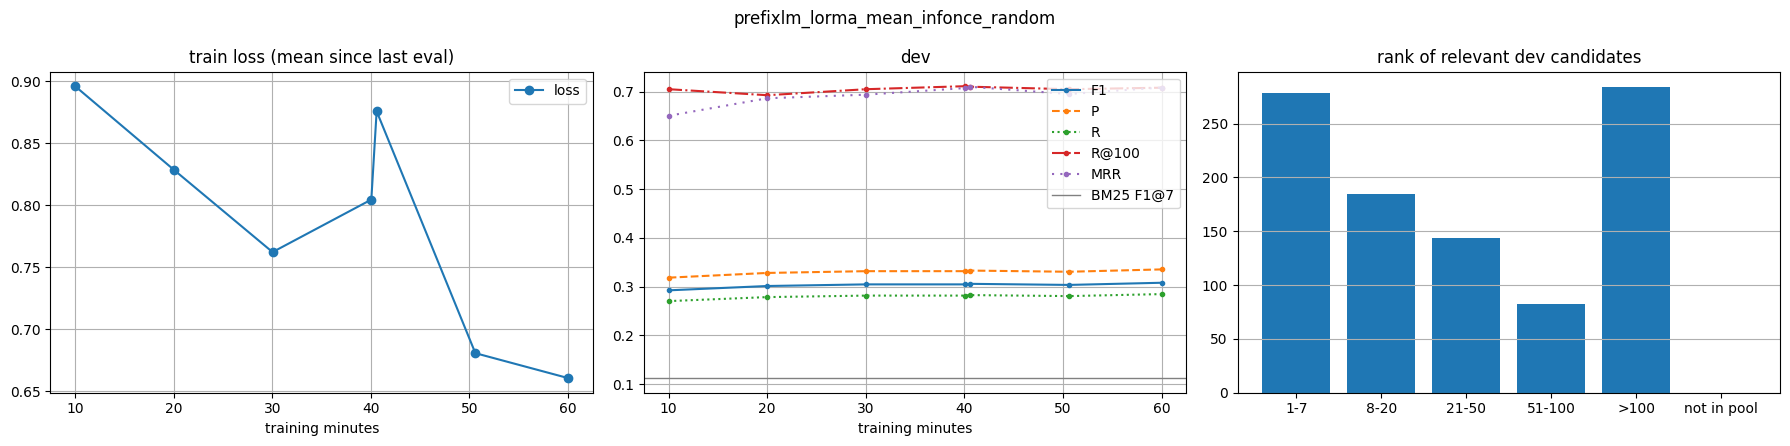

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

{
 "run": "prefixlm_lorma_mean_infonce_random",
 "params_total": 109824768,
 "params_trainable": 294912,
 "params_final": 109529856,
 "model_mb": 417.823486328125,
 "train_minutes": 60.02708826859792,
 "peak_gpu_gb": 2.388289024,
 "best": {
  "F1": 0.3079488604780434,
  "epoch": 2,
  "step": 1960
 }
}
{
 "dev": {
  "F1": 0.30906058921623125,
  "P": 0.3365617433414044,
  "R": 0.2857142857142857,
  "R@7": 0.2857142857142857,
  "R@20": 0.47584789311408016,
  "R@50": 0.6238437821171634,
  "R@100": 0.7081192189105858,
  "MRR": 0.7085228052223622,
  "tp": 278,
  "fp": 548,
  "fn": 695,
  "zero_hit_queries": 16,
  "n": 118
 }
}


In [16]:
train_encode_seconds = 0.0
if SAVE_TRAIN_SCORES:
    t0 = time.time(); TR_S, _, _ = run_split(model, "train"); train_encode_seconds = time.time() - t0
    np.savez_compressed(f"{RUN_DIR}/train_scores.npz", query_ids=np.array(QIDS["train"]), cand_ids=np.array(CIDS["train"]),
                        logits=(TR_S / TAU).astype(np.float32))
    r_tr = rank_metrics(final_scores(TR_S, "train", model_only=True), "train")
    print(f"train_scores.npz: {TR_S.shape[0]} queries x {TR_S.shape[1]} candidates ({train_encode_seconds:.0f}s);  this "
          f"model on the training queries: {fmt(r_tr)}")
    del TR_S

info = {
    "run": RUN_NAME, "arch": ARCH, "method": METHOD, "repr": REPR, "doc_pool": DOC_POOL, "loss": LOSS,
    "neg_source": NEG_SOURCE, "attn": ATTN, "bart_mode": BART_MODE, "p1_repo": P1_REPOS[ARCH],
    "layers": STUDENT_LAYERS if STUDENT else "all", "kept_blocks": model.kept, "n_train_queries": len(TRAIN_Q),
    "n_train_pairs": len(PAIRS), "pool_sizes": {s: len(CIDS[s]) for s in SPLITS},
    "config": {k: globals()[k] for k in ("SEED", "CHUNK_LEN", "CHUNK_STRIDE", "CHUNK_SELECT", "MAX_CHUNKS", "MAX_CHUNKS_PRED",
                                         "POOL", "ATT_HIDDEN", "GRU_HIDDEN", "PROJ", "PROJ_DIM", "SIM", "TAU", "EXCLUDE_SELF",
                                         "RERANK_TOPN", "FUSION_WEIGHT", "BM25_K1", "BM25_B", "BM25_STOPWORDS",
                                         "PAIRS_PER_BATCH", "HARD_NEGS", "NEG_DEPTH", "EPOCHS", "MAX_TRAIN_MINUTES",
                                         "EVAL_EVERY_MINUTES", "PATIENCE", "GRAD_ACCUM", "GRAD_CKPT", "LR", "HEAD_LR",
                                         "WEIGHT_DECAY", "WARMUP_FRAC", "GRAD_CLIP", "PARTIAL_TOP", "ADAPT_TARGETS", "RANK",
                                         "ALPHA", "QLORA_BLOCK", "QLORA_DOUBLE_QUANT", "LORMA_VARIANT", "IA3_OUT", "IA3_IN",
                                         "PROMPT_LEN", "TEACHER_RUN", "STUDENT_LAYERS", "KD_T", "KD_ALPHA")},
    "params_total": TOTAL_PARAMS, "params_trainable": TRAINABLE_PARAMS, "params_final": FINAL_PARAMS,
    "model_mb": FINAL_MB, "qlora": QUANT_INFO, "vector_dim": model.dim,
    "train_minutes": train_seconds / 60, "peak_gpu_gb": PEAK_TRAIN_GB, "best": best, "stop": stop,
    "dev": dev, "dev_model_only": dev_model, "reference": REFERENCE, "dev_efficiency": DEV_INFO,
    "dev_encode_seconds": dev_seconds, "test_encode_seconds": test_seconds, "train_encode_seconds": train_encode_seconds,
    "dev_by_n_relevant": BY_NGOLD, "dev_by_query_length": BY_QLEN, "dev_relevant_rank_bins": RANK_BINS,
    "dev_hubs": HUBS, "dev_overlap_with_bm25_top7": OVERLAP_BM25, "dev_chunk_attention": ATTN_INFO,
    "teacher": teacher_info and {"run": TEACHER_RUN, "arch": teacher_info["arch"], "method": teacher_info["method"],
                                 "params": teacher_info["params_final"], "model_mb": teacher_info["model_mb"],
                                 "dev_F1": teacher_info["dev"]["F1"], "dev_encode_seconds": teacher_info["dev_encode_seconds"],
                                 "dev_candidates_per_s": teacher_info["dev_efficiency"]["candidates_per_s"]},
    "history": history,
}
json.dump(info, open(f"{RUN_DIR}/run_config.json", "w"), indent=1, default=float)
if SAVE_WEIGHTS:
    torch.save(model.state_dict(), f"{RUN_DIR}/model.pt")

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
tm = [h["train_minutes"] for h in history]
ax[0].plot(tm, [h["train_loss"] for h in history], marker="o", label="loss")
if any(h["kd_loss"] is not None for h in history):
    ax[0].plot(tm, [h["kd_loss"] for h in history], marker=".", ls="--", label="kd term")
ax[0].set_title("train loss (mean since last eval)"); ax[0].legend()
for k, st in (("dev_F1", "-"), ("dev_P", "--"), ("dev_R", ":"), ("dev_R@100", "-."), ("dev_MRR", (0, (1, 3)))):
    ax[1].plot(tm, [h[k] for h in history], marker=".", ls=st, label=k[4:])
ax[1].axhline(REFERENCE["bm25"]["F1"], color="grey", lw=1, label="BM25 F1@7")
ax[1].set_title("dev"); ax[1].legend()
for a in ax[:2]: a.set_xlabel("training minutes"); a.grid(True)
ax[2].bar(list(RANK_BINS), list(RANK_BINS.values())); ax[2].set_title("rank of relevant dev candidates"); ax[2].grid(True, axis="y")
fig.suptitle(RUN_NAME); plt.tight_layout(); plt.savefig(f"{RUN_DIR}/curves.png", dpi=130); plt.show()

api.create_repo(P7_REPO, private=True, exist_ok=True)
hub_push(lambda: api.upload_folder(folder_path=RUN_DIR, path_in_repo=f"runs/{RUN_NAME}", repo_id=P7_REPO,
                                   commit_message=f"{RUN_NAME} dev F1@7 {dev['F1']:.4f}"), f"runs/{RUN_NAME}")
try:
    from google.colab import files
    files.download(ZIP)
except Exception:
    pass
print(json.dumps({k: info[k] for k in ("run", "params_total", "params_trainable", "params_final", "model_mb",
                                       "train_minutes", "peak_gpu_gb", "best")}, indent=1, default=float))
print(json.dumps({"dev": dev}, indent=1, default=float))

## All Phase-7 runs so far (from `cs781-p7`, every account)
A table of the saved runs and a mechanical count against the §13.2 requirements (which §13.2.1 techniques have runs).
Counts only — whether two runs are "substantially different" is your judgement.

In [17]:
TECHNIQUE = {"full": "full", "partial": "partial/layer-wise", "qlora": "qlora", "lorma": "lorma", "prompt": "prompt tuning",
             "ia3": "ia3", "kd": "kd"}
runs = sorted({f.split("/")[1] for f in api.list_repo_files(P7_REPO) if f.startswith("runs/") and f.endswith("/run_config.json")})
rows = []
for r in runs:
    try:
        rows.append(json.load(open(hf_hub_download(P7_REPO, f"runs/{r}/run_config.json", token=HF_TOKEN, force_download=True))))
    except Exception as e:
        print(f"  !! {r}: {e!r}")
print(f"{'run':44s} {'arch':11s} {'method':8s} {'repr':6s} {'loss':8s} {'neg':7s} {'params':>7s} {'trainable':>10s} {'MB':>6s} "
      f"{'F1@7':>7s} {'P@7':>7s} {'R@7':>7s} {'R@100':>7s} {'model F1':>8s} {'train min':>9s} {'cand/s':>7s}")
for x in rows:
    dv, dm = x["dev"], x["dev_model_only"]
    print(f"{x['run'][:44]:44s} {x['arch']:11s} {x['method']:8s} {x['repr'] if x['repr'] == 'chunks' else x['doc_pool']:6s} "
          f"{x['loss']:8s} {x['neg_source']:7s} {x['params_final']/1e6:6.1f}M {x['params_trainable']/1e6:9.3f}M "
          f"{x['model_mb']:6.0f} {dv['F1']:7.4f} {dv['P']:7.4f} {dv['R']:7.4f} {dv['R@100']:7.4f} {dm['F1']:8.4f} "
          f"{x['train_minutes']:9.1f} {x['dev_efficiency']['candidates_per_s']:7.1f}")
archs = {x["arch"] for x in rows}; techs = {TECHNIQUE[x["method"]] for x in rows}
print(f"\nPhase-1 models with runs: {sorted(archs)}  (missing: {sorted({'llama', 'bart', 'prefixlm', 'mistral_swa'} - archs)})")
print(f"§13.2.1 techniques with runs: {sorted(techs)}  (non-KD: {len(techs - {'kd'})})  "
      f"LoRMA: {'lorma' in techs}  KD: {'kd' in techs}")

run_config.json:   0%|          | 0.00/7.46k [00:00<?, ?B/s]

run_config.json:   0%|          | 0.00/8.49k [00:00<?, ?B/s]

run                                          arch        method   repr   loss     neg      params  trainable     MB    F1@7     P@7     R@7   R@100 model F1 train min  cand/s
bart_lorma_mean_infonce_random               bart        lorma    mean   infonce  random    67.9M     0.147M    259  0.3369  0.3668  0.3114  0.6978   0.3369      31.4    36.8
prefixlm_lorma_mean_infonce_random           prefixlm    lorma    mean   infonce  random   109.5M     0.295M    418  0.3091  0.3366  0.2857  0.7081   0.3091      60.0    13.4

Phase-1 models with runs: ['bart', 'prefixlm']  (missing: ['llama', 'mistral_swa'])
§13.2.1 techniques with runs: ['lorma']  (non-KD: 1)  LoRMA: True  KD: False
